# Intel Image Classification — Preprocessing Pipeline

**Dataset:** https://www.kaggle.com/datasets/puneet6060/intel-image-classification  
**Classes:** Buildings · Forest · Glacier · Mountain · Sea · Street  
**Models:** VGG-16 · MobileNetV2 · SqueezeNet · ResNet-50 · ShuffleNetV2 · GhostNet · InceptionV3 · EfficientNet-B0 · MNASNet

---

| Step | Why Needed |
|------|------------|
| Resizing | 8 models→224×224, InceptionV3→299×299 |
| Normalization | All 9 use ImageNet pretrained weights |
| Data Augmentation | ~2.3k images/class — prevents overfitting |
| Train/Val Split | No built-in val set in dataset |
| DataLoaders | Batching + GPU pinning for all 9 models |
| EDA & Distribution | Detect class imbalance before training |
| **Corrupt Image Scan** | One bad file crashes a full epoch |
| **Dataset Mean/Std** | Verify ImageNet stats fit this dataset |
| **WeightedRandomSampler** | Fix class imbalance at loader level |
| **Test-Time Augmentation** | Multi-crop inference, zero extra training |

---
## Section 1 — Install & Import Dependencies

In [1]:
!pip install -q kaggle timm opendatasets scikit-learn pandas seaborn tqdm

In [1]:
import os, random, warnings
import time
import copy
import json
import multiprocessing as mp
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import opendatasets as od
from PIL import Image, UnidentifiedImageError

import torch, torchvision
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torch.cuda.amp import autocast, GradScaler
from torch.utils.data import DataLoader, Subset, WeightedRandomSampler
from torchvision import models
from torchvision.datasets import ImageFolder

import timm
from tqdm import tqdm
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    )

warnings.filterwarnings('ignore')
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print(f"PyTorch : {torch.__version__}")
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device  : {DEVICE}")

DATALOADER_NUM_WORKERS = 8
DATALOADER_PERSISTENT_WORKERS = True

# Prefer spawn context in notebooks to reduce multiprocessing teardown issues.
try:
    mp.set_start_method('spawn')
except RuntimeError:
    pass

PyTorch : 2.5.1+cu121
Device  : cuda


---
## Section 2 — Download Dataset from Kaggle

Uses [`opendatasets`](https://github.com/JovianML/opendatasets) — no file upload needed.  
When the cell runs it will prompt for:
- **Kaggle username** (your Kaggle account name)
- **Kaggle Key** (the `key` field from `kaggle.json` → Kaggle → Settings → API → Create New Token)

In [ ]:
od.download(
    'https://www.kaggle.com/datasets/puneet6060/intel-image-classification',
    data_dir='/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset'
)
print('Download complete.')

Please provide your Kaggle credentials to download this dataset. Learn more: http://bit.ly/kaggle-creds
Your Kaggle username:Your Kaggle Key:Dataset URL: https://www.kaggle.com/datasets/puneet6060/intel-image-classification


100%|██████████| 346M/346M [00:00<00:00, 387MB/s] 



Download complete.


In [2]:
# opendatasets saves to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/
DATA_ROOT = Path('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification')
TRAIN_DIR = DATA_ROOT / 'seg_train' / 'seg_train'
TEST_DIR  = DATA_ROOT / 'seg_test'  / 'seg_test'

CLASS_NAMES = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir()])
NUM_CLASSES = len(CLASS_NAMES)
print(f'Classes ({NUM_CLASSES}): {CLASS_NAMES}')
print(f'Train : {TRAIN_DIR}')
print(f'Test  : {TEST_DIR}')

Classes (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Train : /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/seg_train/seg_train
Test  : /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/seg_test/seg_test


---
## Section 3 — Exploratory Data Analysis

In [3]:
def count_images(root):
    return {c: len(list((root/c).glob('*.jpg')))+len(list((root/c).glob('*.png'))) for c in CLASS_NAMES}
train_counts = count_images(TRAIN_DIR)
test_counts  = count_images(TEST_DIR)
print(f"{'Class':<12} {'Train':>8} {'Test':>8}"); print('-'*30)
for c in CLASS_NAMES: print(f"{c:<12} {train_counts[c]:>8} {test_counts[c]:>8}")
print('-'*30)
print(f"{'TOTAL':<12} {sum(train_counts.values()):>8} {sum(test_counts.values()):>8}")

Class           Train     Test
------------------------------
buildings        2191      437
forest           2271      474
glacier          2404      553
mountain         2512      525
sea              2274      510
street           2382      501
------------------------------
TOTAL           14034     3000


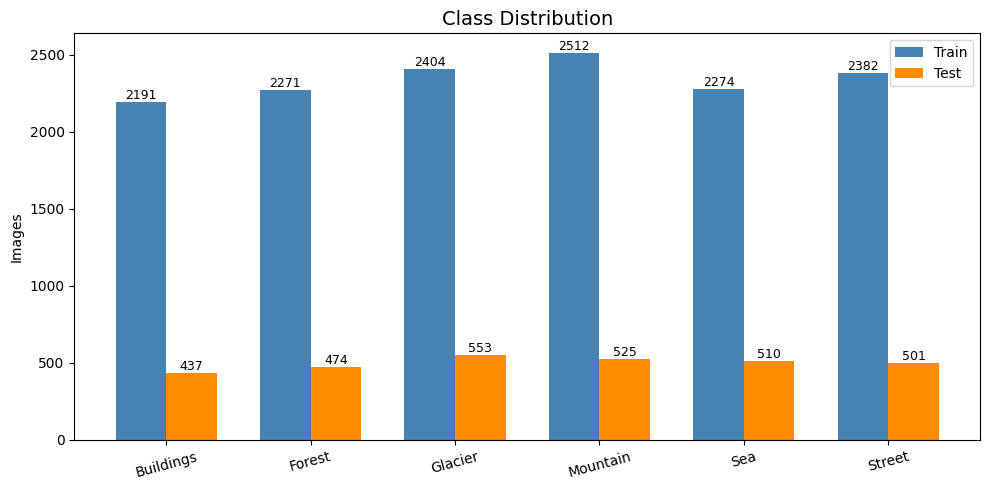

Max/Min ratio: 1.15 — balanced


In [4]:
x,bw = np.arange(NUM_CLASSES),0.35
fig,ax = plt.subplots(figsize=(10,5))
b1=ax.bar(x-bw/2,[train_counts[c] for c in CLASS_NAMES],bw,label='Train',color='steelblue')
b2=ax.bar(x+bw/2,[test_counts[c]  for c in CLASS_NAMES],bw,label='Test', color='darkorange')
ax.set_xticks(x); ax.set_xticklabels([c.capitalize() for c in CLASS_NAMES],rotation=15)
ax.set_title('Class Distribution',fontsize=14); ax.set_ylabel('Images'); ax.legend()
for b in list(b1)+list(b2):
    ax.text(b.get_x()+b.get_width()/2,b.get_height()+20,str(int(b.get_height())),ha='center',fontsize=9)
plt.tight_layout(); plt.savefig('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/class_distribution.png',dpi=150); plt.show()
vals=list(train_counts.values()); ratio=max(vals)/min(vals)
print(f"Max/Min ratio: {ratio:.2f} — {'balanced' if ratio<1.5 else 'imbalance detected → run Section 12'}")

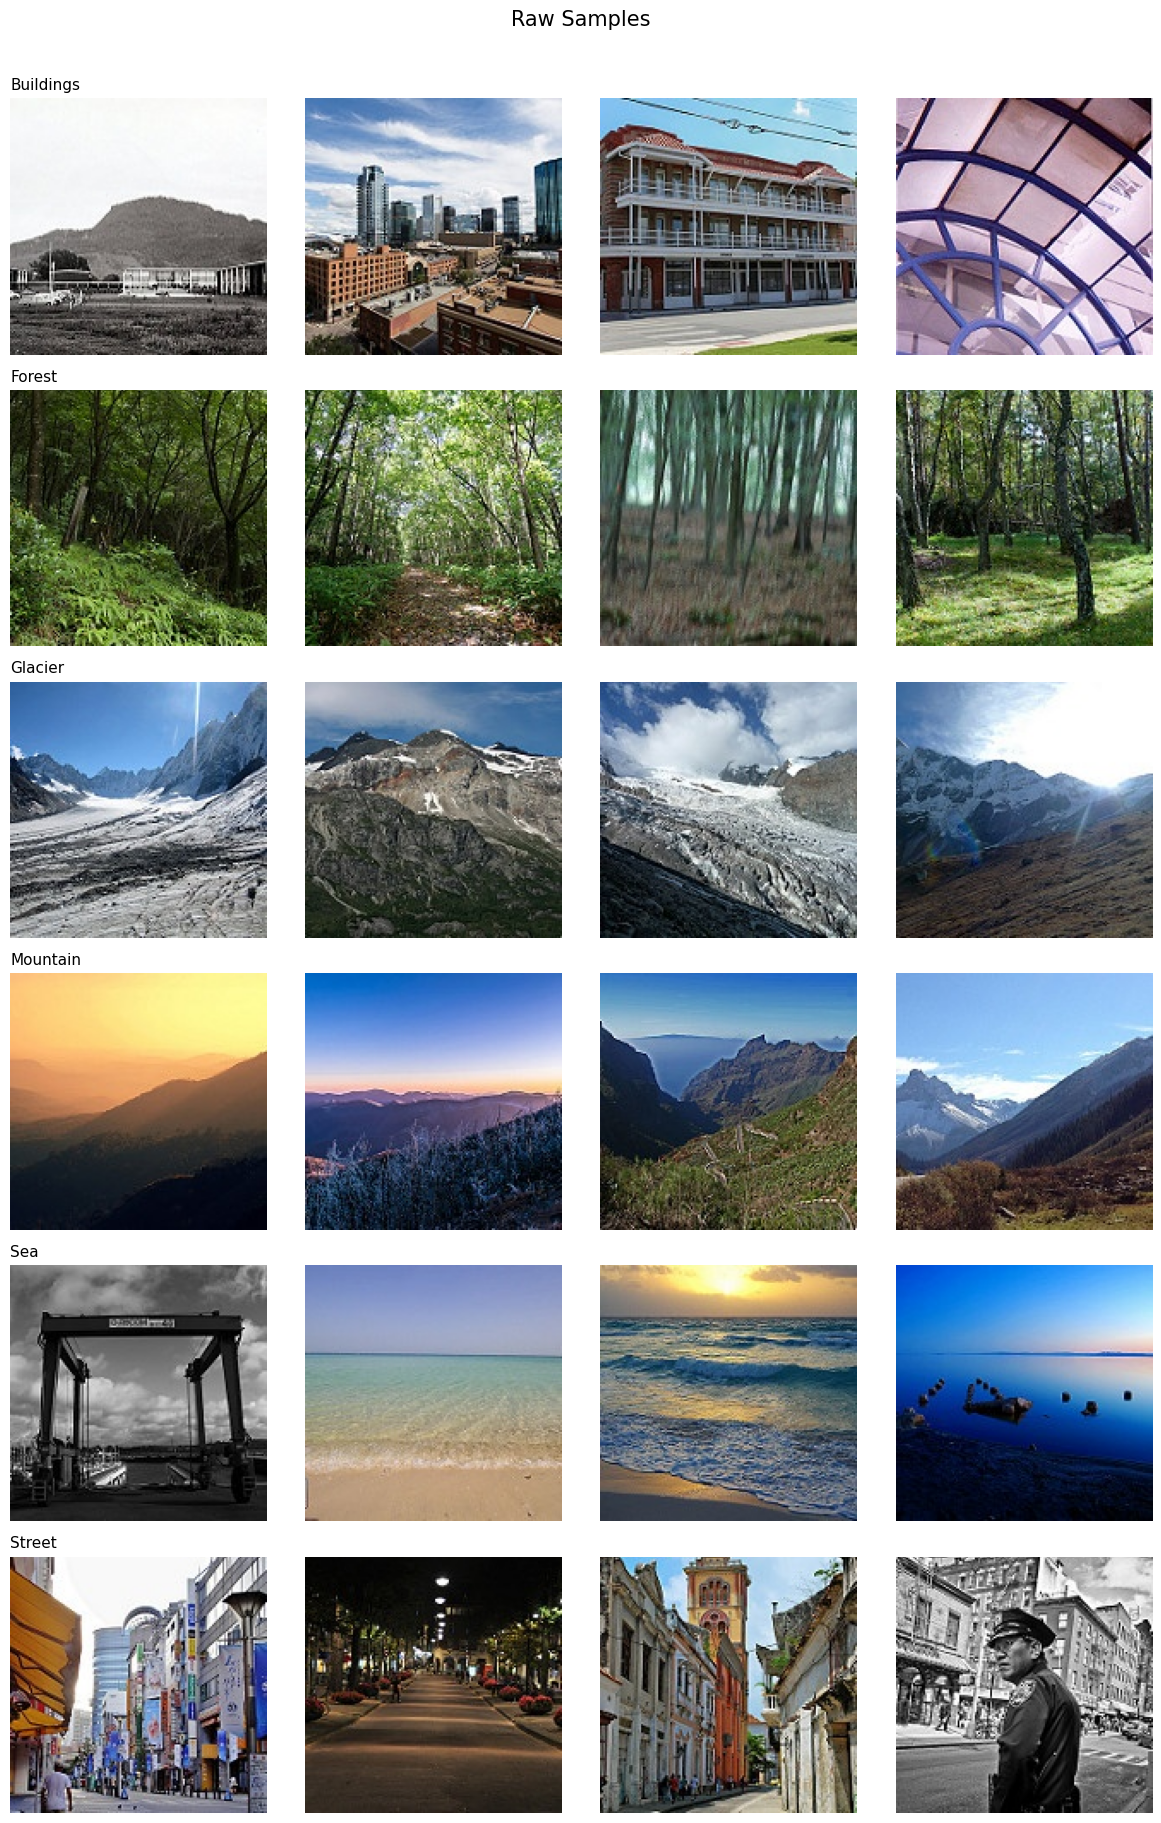

In [5]:
fig,axes=plt.subplots(NUM_CLASSES,4,figsize=(12,NUM_CLASSES*3))
for row,cls in enumerate(CLASS_NAMES):
    for col,p in enumerate(list((TRAIN_DIR/cls).glob('*.jpg'))[:4]):
        axes[row,col].imshow(Image.open(p).convert('RGB')); axes[row,col].axis('off')
        if col==0: axes[row,col].set_title(cls.capitalize(),fontsize=11,loc='left')
fig.suptitle('Raw Samples',fontsize=15,y=1.01)
plt.tight_layout(); plt.savefig('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/raw_samples.png',dpi=150,bbox_inches='tight'); plt.show()

In [6]:
print(f"{'Class':<12} {'W x H':>12} {'Mode':>6}"); print('-'*32)
for cls in CLASS_NAMES:
    img=Image.open(next((TRAIN_DIR/cls).glob('*.jpg'))).convert('RGB')
    print(f"{cls:<12} {str(img.size):>12} {img.mode:>6}")

Class               W x H   Mode
--------------------------------
buildings      (150, 150)    RGB
forest         (150, 150)    RGB
glacier        (150, 150)    RGB
mountain       (150, 150)    RGB
sea            (150, 150)    RGB
street         (150, 150)    RGB


---
## Section 4 — Model Input Size Requirements

| Models | Input Size | Notes |
|--------|------------|-------|
| VGG-16 / MobileNetV2 / SqueezeNet / ResNet-50 | 224×224 | Standard size |
| ShuffleNetV2 / GhostNet / EfficientNet-B0 / MNASNet | 224×224 | Standard size |
| **InceptionV3** | **299×299** | Only exception |

In [7]:
MODEL_CONFIGS = {
    'VGG-16':{'input_size':224},'MobileNetV2':{'input_size':224},
    'SqueezeNet':{'input_size':224},'ResNet-50':{'input_size':224},
    'ShuffleNetV2':{'input_size':224},'GhostNet':{'input_size':224},
    'InceptionV3':{'input_size':299},'EfficientNet-B0':{'input_size':224},'MNASNet':{'input_size':224},
}
print("Unique resolutions:",sorted(set(v['input_size'] for v in MODEL_CONFIGS.values())))

Unique resolutions: [224, 299]


---
## Section 5 — Preprocessing Transforms

**Normalization:** ImageNet `mean=[0.485,0.456,0.406]` `std=[0.229,0.224,0.225]`  
**Train aug:** RandomResizedCrop · HorizontalFlip · Rotation(±15°) · ColorJitter  
**Val/Test:** Resize → CenterCrop → Normalize (no augmentation)

In [8]:
IMAGENET_MEAN=[0.485,0.456,0.406]; IMAGENET_STD=[0.229,0.224,0.225]

def build_transforms(sz, train):
    if train:
        return transforms.Compose([
            transforms.RandomResizedCrop(sz,scale=(0.8,1.0),ratio=(0.75,1.33),
                interpolation=transforms.InterpolationMode.BILINEAR),
            transforms.RandomHorizontalFlip(0.5),
            transforms.RandomRotation(15),
            transforms.ColorJitter(brightness=0.3,contrast=0.3,saturation=0.2,hue=0.05),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])
    r=int(sz*1.14)
    return transforms.Compose([
        transforms.Resize(r,interpolation=transforms.InterpolationMode.BILINEAR),
        transforms.CenterCrop(sz),transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD)])

TRANSFORMS={224:{'train':build_transforms(224,True),'val':build_transforms(224,False),'test':build_transforms(224,False)},
            299:{'train':build_transforms(299,True),'val':build_transforms(299,False),'test':build_transforms(299,False)}}
print("Transforms ready.")
print("\n── Train 224:"); print(TRANSFORMS[224]['train'])
print("\n── Val/Test 224:"); print(TRANSFORMS[224]['val'])
print("\n── Train 299 (InceptionV3):"); print(TRANSFORMS[299]['train'])

Transforms ready.

── Train 224:
Compose(
    RandomResizedCrop(size=(224, 224), scale=(0.8, 1.0), ratio=(0.75, 1.33), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.7, 1.3), contrast=(0.7, 1.3), saturation=(0.8, 1.2), hue=(-0.05, 0.05))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

── Val/Test 224:
Compose(
    Resize(size=255, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

── Train 299 (InceptionV3):
Compose(
    RandomResizedCrop(size=(299, 299), scale=(0.8, 1.0), ratio=(0.75, 1.33), interpolation=bilinear, antialias=True)
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-15.0, 15.0], interpolation=nearest, expand=False, fill=0)
    ColorJitter(brightness=(0.7, 1.3), 

---
## Section 6 — Stratified Train / Validation Split

20% of `seg_train` → validation set (stratified per class).  
`seg_test` is kept as final held-out test set.

In [9]:
VAL_SPLIT=0.20; BATCH_SIZE=32

def make_stratified_split(ds, frac, seed=42):
    rng=np.random.default_rng(seed)
    ci={c:[] for c in range(NUM_CLASSES)}
    for i,(_,l) in enumerate(ds.samples): ci[l].append(i)
    tr,vl=[],[]
    for idx in ci.values():
        idx=np.array(idx); rng.shuffle(idx); n=int(len(idx)*frac)
        vl.extend(idx[:n].tolist()); tr.extend(idx[n:].tolist())
    return tr,vl

class TransformSubset(torch.utils.data.Dataset):
    def __init__(self,sub,tf): self.sub=sub; self.tf=tf; self.classes=sub.dataset.classes
    def __len__(self): return len(self.sub)
    def __getitem__(self,i):
        img,l=self.sub[i]; return (self.tf(img) if self.tf else img),l

raw_train=ImageFolder(root=TRAIN_DIR,transform=None)
raw_test =ImageFolder(root=TEST_DIR, transform=None)
train_idx,val_idx=make_stratified_split(raw_train,VAL_SPLIT)
print(f"Train split : {len(train_idx)}  |  Val split : {len(val_idx)}  |  Test : {len(raw_test.samples)}")

Train split : 11230  |  Val split : 2804  |  Test : 3000


In [10]:
tr_l=[raw_train.samples[i][1] for i in train_idx]
vl_l=[raw_train.samples[i][1] for i in val_idx]
print(f"{'Class':<12} {'Train':>8} {'Val':>8} {'Val%':>8}"); print('-'*40)
for n,i in raw_train.class_to_idx.items():
    tr=tr_l.count(i); vl=vl_l.count(i)
    print(f"{n:<12} {tr:>8} {vl:>8} {vl/(tr+vl)*100:>7.1f}%")

Class           Train      Val     Val%
----------------------------------------
buildings        1753      438    20.0%
forest           1817      454    20.0%
glacier          1924      480    20.0%
mountain         2010      502    20.0%
sea              1820      454    20.0%
street           1906      476    20.0%


---
## Section 7 — DataLoaders

`get_dataloaders(model_name)` → `(train_loader, val_loader, test_loader, class_names)`

In [13]:
def get_dataloaders(model_name, batch_size=32, num_workers=None):
    if num_workers is None:
        num_workers = DATALOADER_NUM_WORKERS

    sz = MODEL_CONFIGS[model_name]['input_size']
    tf = TRANSFORMS[sz]

    # Spawn-safe approach in notebooks: avoid custom dataset wrapper classes.
    tr_base = ImageFolder(root=TRAIN_DIR, transform=tf['train'])
    vl_base = ImageFolder(root=TRAIN_DIR, transform=tf['val'])
    ts_s = ImageFolder(root=TEST_DIR, transform=tf['test'])

    tr_s = Subset(tr_base, train_idx)
    vl_s = Subset(vl_base, val_idx)

    pin = (DEVICE.type == 'cuda')
    persistent = DATALOADER_PERSISTENT_WORKERS and num_workers > 0
    kwargs = {'multiprocessing_context': 'spawn'} if num_workers > 0 else {}

    return (
        DataLoader(tr_s, batch_size=batch_size, shuffle=True,  num_workers=num_workers, pin_memory=pin, persistent_workers=persistent, **kwargs),
        DataLoader(vl_s, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin, persistent_workers=persistent, **kwargs),
        DataLoader(ts_s, batch_size=batch_size, shuffle=False, num_workers=num_workers, pin_memory=pin, persistent_workers=persistent, **kwargs),
        tr_base.classes,
    )

print("get_dataloaders() ready.")

get_dataloaders() ready.


In [14]:
print(f"{'Model':<16} {'Size':>8} {'Batch shape':>24}"); print('-'*50)
for name,cfg in MODEL_CONFIGS.items():
    ldr,_,_,_=get_dataloaders(name,batch_size=4); imgs,_=next(iter(ldr))
    sz=cfg['input_size']
    print(f"{name:<16} {str(sz)+'x'+str(sz):>8} {str(tuple(imgs.shape)):>24}")
print("\nAll shapes verified")

Model                Size              Batch shape
--------------------------------------------------
VGG-16            224x224         (4, 3, 224, 224)
MobileNetV2       224x224         (4, 3, 224, 224)
SqueezeNet        224x224         (4, 3, 224, 224)
ResNet-50         224x224         (4, 3, 224, 224)
ShuffleNetV2      224x224         (4, 3, 224, 224)
GhostNet          224x224         (4, 3, 224, 224)
InceptionV3       299x299         (4, 3, 299, 299)
EfficientNet-B0   224x224         (4, 3, 224, 224)
MNASNet           224x224         (4, 3, 224, 224)

All shapes verified


---
## Section 8 — Visualise Preprocessed Batches

In [15]:
def denorm(t):
    m=torch.tensor(IMAGENET_MEAN).view(3,1,1); s=torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t*s+m).permute(1,2,0).clamp(0,1).numpy()

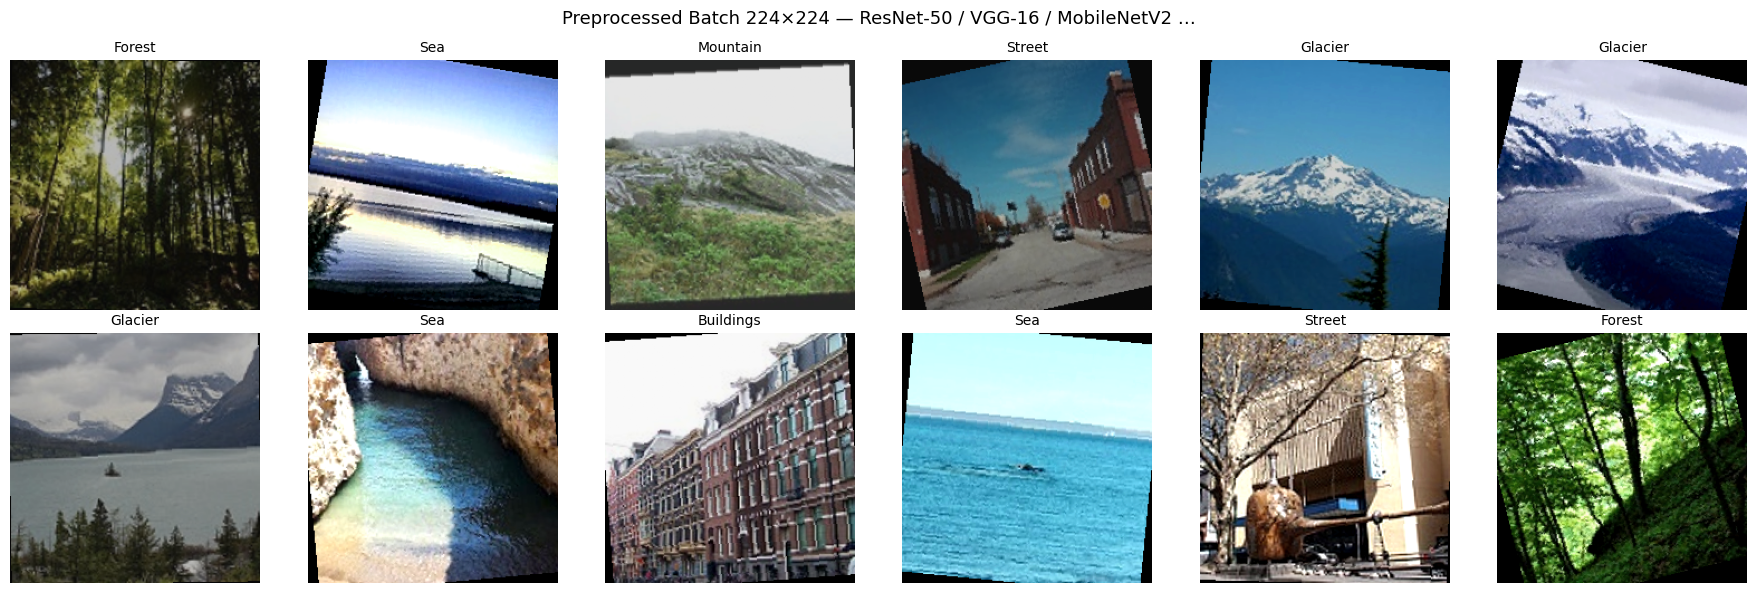

dtype=torch.float32  min=-2.118  max=2.640


In [16]:
ldr,_,_,cnames=get_dataloaders('ResNet-50',batch_size=12)
imgs,lbls=next(iter(ldr))
fig,axes=plt.subplots(2,6,figsize=(18,6)); axes=axes.flatten()
for i,(img,lbl) in enumerate(zip(imgs,lbls)):
    axes[i].imshow(denorm(img)); axes[i].set_title(cnames[lbl.item()].capitalize(),fontsize=10); axes[i].axis('off')
fig.suptitle('Preprocessed Batch 224×224 — ResNet-50 / VGG-16 / MobileNetV2 …',fontsize=13)
plt.tight_layout(); plt.savefig('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/batch_224.png',dpi=150,bbox_inches='tight'); plt.show()
print(f"dtype={imgs.dtype}  min={imgs.min():.3f}  max={imgs.max():.3f}")

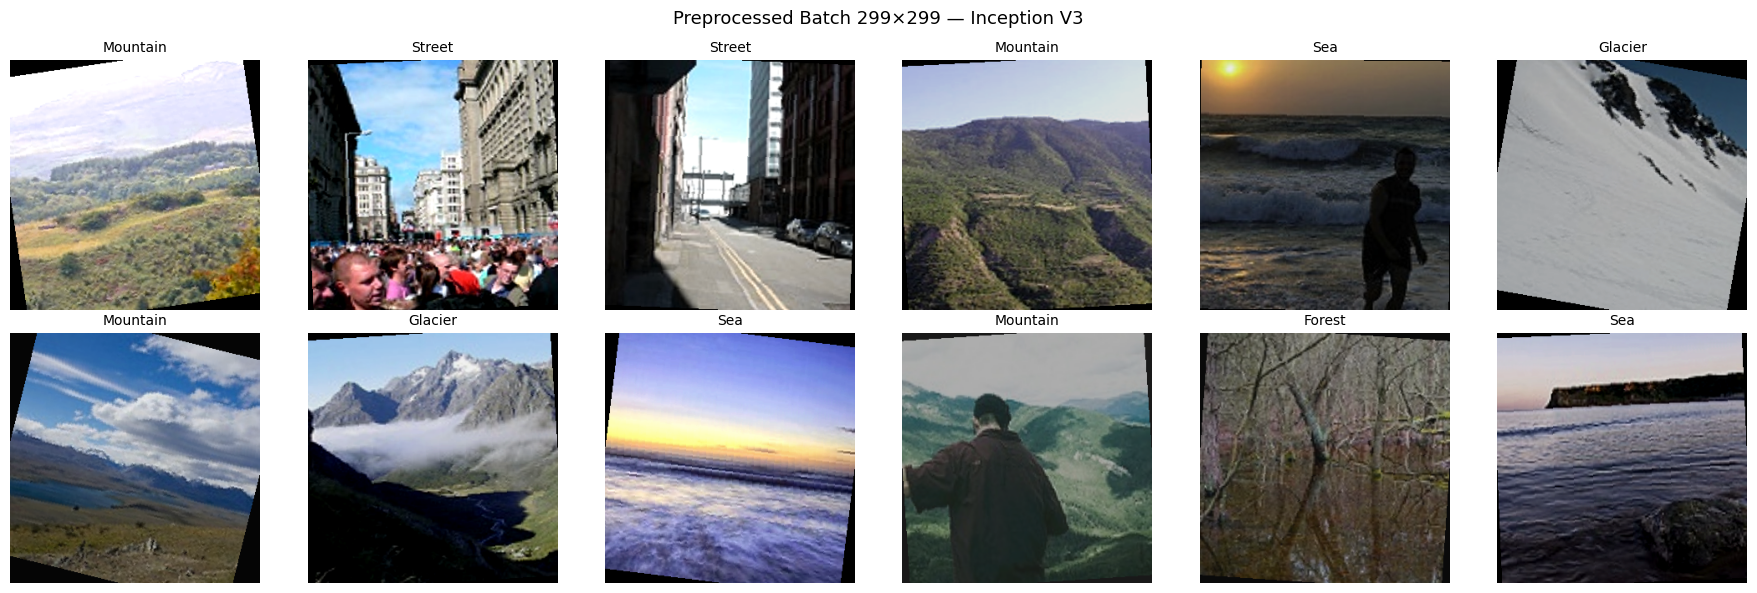

In [17]:
ldr,_,_,_=get_dataloaders('InceptionV3',batch_size=12); imgs,lbls=next(iter(ldr))
fig,axes=plt.subplots(2,6,figsize=(18,6)); axes=axes.flatten()
for i,(img,lbl) in enumerate(zip(imgs,lbls)):
    axes[i].imshow(denorm(img)); axes[i].set_title(cnames[lbl.item()].capitalize(),fontsize=10); axes[i].axis('off')
fig.suptitle('Preprocessed Batch 299×299 — Inception V3',fontsize=13)
plt.tight_layout(); plt.savefig('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/batch_299.png',dpi=150,bbox_inches='tight'); plt.show()

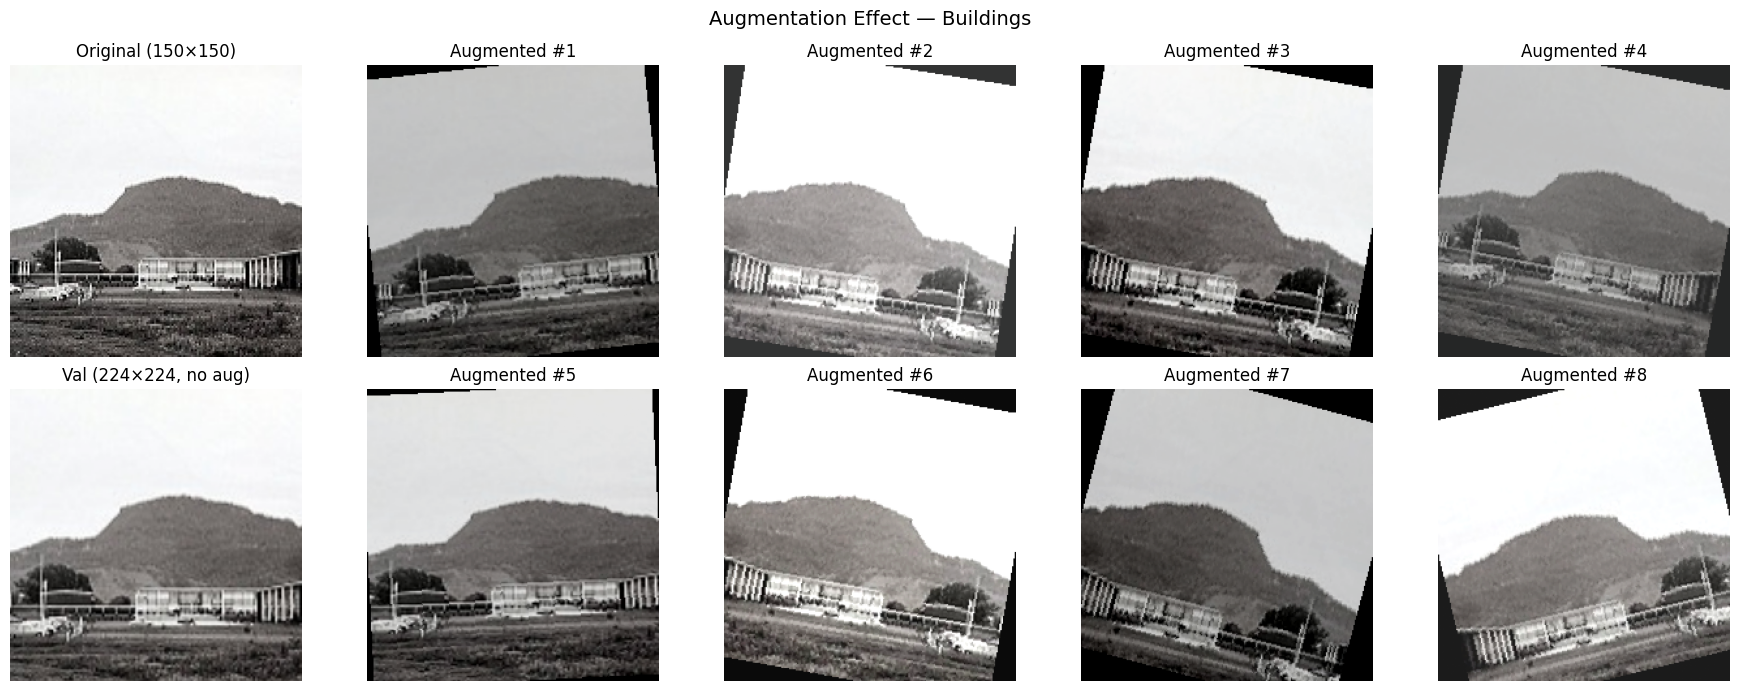

In [18]:
raw_img=Image.open(next((TRAIN_DIR/CLASS_NAMES[0]).glob('*.jpg'))).convert('RGB')
fig,axes=plt.subplots(2,5,figsize=(18,7))
axes[0,0].imshow(raw_img); axes[0,0].set_title('Original (150×150)'); axes[0,0].axis('off')
axes[1,0].imshow(denorm(TRANSFORMS[224]['val'](raw_img)))
axes[1,0].set_title('Val (224×224, no aug)'); axes[1,0].axis('off')
for k,(r,c) in enumerate([(0,1),(0,2),(0,3),(0,4),(1,1),(1,2),(1,3),(1,4)]):
    axes[r,c].imshow(denorm(TRANSFORMS[224]['train'](raw_img)))
    axes[r,c].set_title(f'Augmented #{k+1}'); axes[r,c].axis('off')
fig.suptitle(f'Augmentation Effect — {CLASS_NAMES[0].capitalize()}',fontsize=14)
plt.tight_layout(); plt.savefig('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/augmentation.png',dpi=150,bbox_inches='tight'); plt.show()

---
## Section 9 — Label Encoding & Class Mapping

Explicit mappings needed for confusion matrices and per-class metric reporting.

In [19]:
CLASS_TO_IDX=raw_train.class_to_idx; IDX_TO_CLASS={v:k for k,v in CLASS_TO_IDX.items()}
print("Class → Index:"); [print(f"  {i} → {c}") for c,i in CLASS_TO_IDX.items()]
print(f"\nTotal classes: {NUM_CLASSES}")

Class → Index:
  0 → buildings
  1 → forest
  2 → glacier
  3 → mountain
  4 → sea
  5 → street

Total classes: 6


---
## Section 10 — Corrupt / Unreadable Image Scan

A single corrupt file causes a DataLoader worker to crash mid-epoch, wasting GPU hours.  
**All images** are verified before training. Corrupt files are deleted automatically.

In [20]:
def scan_corrupt(root):
    bad=[]; exts={'.jpg','.jpeg','.png','.bmp'}
    for path in root.rglob('*'):
        if path.suffix.lower() not in exts: continue
        try: img=Image.open(path); img.verify()
        except Exception: bad.append(path)
    return bad

print("Scanning training images …"); bad_tr=scan_corrupt(TRAIN_DIR)
print("Scanning test images …");     bad_ts=scan_corrupt(TEST_DIR)

total=len(bad_tr)+len(bad_ts)
if total==0:
    print("\nNo corrupt images found — all files readable.")
else:
    print(f"\n⚠ {total} corrupt file(s) found:")
    for p in bad_tr+bad_ts: print(f"  {p}")
    for p in bad_tr+bad_ts: p.unlink()
    print("\nCorrupt files deleted — re-run ImageFolder cells before training.")

Scanning training images …
Scanning test images …

No corrupt images found — all files readable.


---
## Section 11 — Dataset Mean & Std Computation

Compute the **actual** per-channel mean/std of this dataset and compare to ImageNet values.  
> If max channel difference < 0.05 → ImageNet stats are fine.  
> Otherwise, replace `IMAGENET_MEAN`/`IMAGENET_STD` with the dataset values and rebuild `TRANSFORMS`.

In [21]:
_tf =transforms.Compose([transforms.Resize((224,224)),transforms.ToTensor()])
_ds =ImageFolder(root=TRAIN_DIR,transform=_tf)
_nw = max(0, DATALOADER_NUM_WORKERS)
_kwargs = {'multiprocessing_context': 'spawn'} if _nw > 0 else {}
_ldr=DataLoader(_ds,batch_size=64,shuffle=False,num_workers=_nw,persistent_workers=(_nw > 0),**_kwargs)
ch_sum=torch.zeros(3); ch_sq=torch.zeros(3); npix=0
for imgs,_ in _ldr:
    ch_sum+=imgs.sum([0,2,3]); ch_sq+=(imgs**2).sum([0,2,3])
    npix+=imgs.shape[0]*imgs.shape[2]*imgs.shape[3]
DATASET_MEAN=(ch_sum/npix).tolist()
DATASET_STD=((ch_sq/npix-torch.tensor(DATASET_MEAN)**2)**0.5).tolist()
print(f"Dataset  mean: {[round(v,4) for v in DATASET_MEAN]}")
print(f"Dataset  std : {[round(v,4) for v in DATASET_STD]}")
print(f"ImageNet mean: {IMAGENET_MEAN}")
print(f"ImageNet std : {IMAGENET_STD}")
diffs=[abs(DATASET_MEAN[i]-IMAGENET_MEAN[i]) for i in range(3)]+[abs(DATASET_STD[i]-IMAGENET_STD[i]) for i in range(3)]
print(f"\nMax channel diff: {max(diffs):.4f}")


Dataset  mean: [0.4302, 0.4575, 0.4539]
Dataset  std : [0.2602, 0.2587, 0.2905]
ImageNet mean: [0.485, 0.456, 0.406]
ImageNet std : [0.229, 0.224, 0.225]

Max channel diff: 0.0655


---
## Section 12 — WeightedRandomSampler (Class Imbalance Fix)

Assigns each training sample a weight **inversely proportional** to its class frequency.  
Replaces `shuffle=True` in the training loader — val/test loaders unchanged.  
Use `get_dataloaders_balanced()` when Section 3 shows imbalance (ratio > 1.5).

In [22]:
def compute_sample_weights(ds, indices):
    labels=np.array([ds.samples[i][1] for i in indices])
    freq=np.bincount(labels,minlength=NUM_CLASSES).astype(float)
    cw=1.0/np.where(freq>0,freq,1.0)
    return torch.tensor(cw[labels],dtype=torch.float)

def get_dataloaders_balanced(model_name,batch_size=32,num_workers=None):
    if num_workers is None:
        num_workers = DATALOADER_NUM_WORKERS

    sz=MODEL_CONFIGS[model_name]['input_size']; tf=TRANSFORMS[sz]
    tr_s=TransformSubset(Subset(raw_train,train_idx),tf['train'])
    vl_s=TransformSubset(Subset(raw_train,val_idx),  tf['val'])
    ts_s=ImageFolder(root=TEST_DIR,transform=tf['test'])
    sampler=WeightedRandomSampler(compute_sample_weights(raw_train,train_idx),len(train_idx),replacement=True)

    pin = (DEVICE.type == 'cuda')
    persistent = DATALOADER_PERSISTENT_WORKERS and num_workers > 0
    kwargs = {'multiprocessing_context': 'spawn'} if num_workers > 0 else {}

    return (DataLoader(tr_s,batch_size=batch_size,sampler=sampler,num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
            DataLoader(vl_s,batch_size=batch_size,shuffle=False, num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
            DataLoader(ts_s,batch_size=batch_size,shuffle=False, num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
            raw_train.classes)
print("get_dataloaders_balanced() ready.")

get_dataloaders_balanced() ready.


In [23]:
# Spawn-safe dataloader overrides for notebook multiprocessing

def get_dataloaders(model_name, batch_size=32, num_workers=None):
    if num_workers is None:
        num_workers = DATALOADER_NUM_WORKERS

    sz=MODEL_CONFIGS[model_name]['input_size']; tf=TRANSFORMS[sz]
    tr_base=ImageFolder(root=TRAIN_DIR,transform=tf['train'])
    vl_base=ImageFolder(root=TRAIN_DIR,transform=tf['val'])
    tr_s=Subset(tr_base,train_idx)
    vl_s=Subset(vl_base,val_idx)
    ts_s=ImageFolder(root=TEST_DIR,transform=tf['test'])

    pin = (DEVICE.type == 'cuda')
    persistent = DATALOADER_PERSISTENT_WORKERS and num_workers > 0
    kwargs = {'multiprocessing_context': 'spawn'} if num_workers > 0 else {}

    return (
        DataLoader(tr_s,batch_size=batch_size,shuffle=True, num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
        DataLoader(vl_s,batch_size=batch_size,shuffle=False,num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
        DataLoader(ts_s,batch_size=batch_size,shuffle=False,num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
        raw_train.classes
    )


def get_dataloaders_balanced(model_name,batch_size=32,num_workers=None):
    if num_workers is None:
        num_workers = DATALOADER_NUM_WORKERS

    sz=MODEL_CONFIGS[model_name]['input_size']; tf=TRANSFORMS[sz]
    tr_base=ImageFolder(root=TRAIN_DIR,transform=tf['train'])
    vl_base=ImageFolder(root=TRAIN_DIR,transform=tf['val'])
    tr_s=Subset(tr_base,train_idx)
    vl_s=Subset(vl_base,val_idx)
    ts_s=ImageFolder(root=TEST_DIR,transform=tf['test'])
    sampler=WeightedRandomSampler(compute_sample_weights(raw_train,train_idx),len(train_idx),replacement=True)

    pin = (DEVICE.type == 'cuda')
    persistent = DATALOADER_PERSISTENT_WORKERS and num_workers > 0
    kwargs = {'multiprocessing_context': 'spawn'} if num_workers > 0 else {}

    return (
        DataLoader(tr_s,batch_size=batch_size,sampler=sampler,num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
        DataLoader(vl_s,batch_size=batch_size,shuffle=False, num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
        DataLoader(ts_s,batch_size=batch_size,shuffle=False, num_workers=num_workers,pin_memory=pin,persistent_workers=persistent,**kwargs),
        raw_train.classes
    )

print('Spawn-safe dataloader overrides ready.')

Spawn-safe dataloader overrides ready.


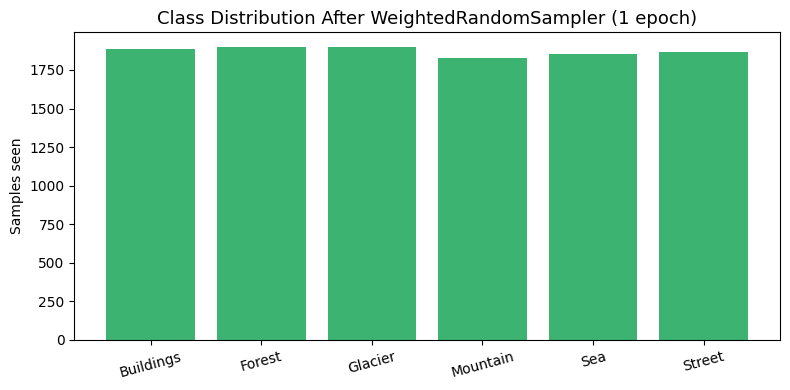

{'buildings': 1886, 'forest': 1897, 'glacier': 1899, 'mountain': 1829, 'sea': 1855, 'street': 1864}


In [25]:
_bl,_,_,_=get_dataloaders_balanced('ResNet-50',batch_size=BATCH_SIZE)
counts=np.zeros(NUM_CLASSES,dtype=int)
for _,lbls in _bl:
    for l in lbls.tolist(): counts[l]+=1
fig,ax=plt.subplots(figsize=(8,4))
ax.bar([c.capitalize() for c in CLASS_NAMES],counts,color='mediumseagreen')
ax.set_title('Class Distribution After WeightedRandomSampler (1 epoch)',fontsize=13)
ax.set_ylabel('Samples seen'); plt.xticks(rotation=15)
plt.tight_layout(); plt.savefig('/media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/balanced_dist.png',dpi=150); plt.show()
print({c:int(n) for c,n in zip(CLASS_NAMES,counts)})

---
## Section 13 — Test-Time Augmentation (TTA)

Pass each test image through **5 crops** or **10 crops**, average softmax → better accuracy.  
No extra training required.

| Mode | Crops | Description |
|------|-------|-------------|
| `5crop` | 5 | 4 corners + centre |
| `10crop` | 10 | 5 crops + horizontal flips |

In [26]:
def build_tta(sz):
    r=int(sz*1.14)
    norm=transforms.Normalize(IMAGENET_MEAN,IMAGENET_STD); to_t=transforms.ToTensor()
    def stack(crops): return torch.stack([norm(to_t(c)) for c in crops])
    return {
        '5crop': transforms.Compose([transforms.Resize(r,interpolation=transforms.InterpolationMode.BILINEAR),
                                      transforms.FiveCrop(sz),transforms.Lambda(stack)]),
        '10crop':transforms.Compose([transforms.Resize(r,interpolation=transforms.InterpolationMode.BILINEAR),
                                      transforms.TenCrop(sz),transforms.Lambda(stack)])}

TTA_TRANSFORMS={224:build_tta(224),299:build_tta(299)}
_img=Image.open(next((TRAIN_DIR/CLASS_NAMES[0]).glob('*.jpg'))).convert('RGB')
for mode in ['5crop','10crop']:
    t=TTA_TRANSFORMS[224][mode](_img)
    print(f"TTA mode={mode:7s} → tensor shape: {tuple(t.shape)}")

TTA mode=5crop   → tensor shape: (5, 3, 224, 224)
TTA mode=10crop  → tensor shape: (10, 3, 224, 224)


In [27]:
def tta_predict(model,image_path,model_name,mode='10crop'):
    """Run TTA inference. Returns predicted class + per-class confidence scores."""
    sz=MODEL_CONFIGS[model_name]['input_size']
    crops=TTA_TRANSFORMS[sz][mode](Image.open(image_path).convert('RGB')).to(DEVICE)
    model.eval()
    with torch.no_grad():
        probs=torch.softmax(model(crops),dim=1).mean(dim=0)
    idx=probs.argmax().item()
    return {'predicted':IDX_TO_CLASS[idx],
            'confidence':{IDX_TO_CLASS[i]:round(probs[i].item(),4) for i in range(NUM_CLASSES)}}

print("tta_predict() ready.")
print("Usage: result = tta_predict(model, 'path/to/img.jpg', 'ResNet-50', mode='10crop')")

tta_predict() ready.
Usage: result = tta_predict(model, 'path/to/img.jpg', 'ResNet-50', mode='10crop')


---
## Section 14 — Final Preprocessing Summary

In [28]:
print("="*65)
print("  PREPROCESSING SUMMARY — Intel Image Classification")
print("="*65)
rows=[
    ("Dataset","Intel Image Classification (Kaggle)"),
    ("Native size","150×150 px | RGB"),
    ("Train images",f"~{sum(train_counts.values())}  (after 80/20 split: {len(train_idx)} train / {len(val_idx)} val)"),
    ("Test images", f"~{sum(test_counts.values())} (held-out, never seen during training)"),
    ("Classes",str(CLASS_NAMES)),("",""),
    ("── Resizing ──",""),
    ("224×224","VGG-16, MobileNetV2, SqueezeNet, ResNet-50, ShuffleNetV2, GhostNet, EfficientNet-B0, MNASNet"),
    ("299×299","Inception V3"),("",""),
    ("── Normalization ──",""),
    ("Mean (RGB)",str(IMAGENET_MEAN)),("Std (RGB)",str(IMAGENET_STD)),("",""),
    ("── Augmentation ──",""),
    ("Training only","RandomResizedCrop · HorizontalFlip · Rotation(±15°) · ColorJitter"),("",""),
    ("── DataLoaders ──",""),
    ("Standard","get_dataloaders(model_name)          → uses shuffle=True"),
    ("Balanced","get_dataloaders_balanced(model_name) → uses WeightedRandomSampler"),
    ("Batch size",str(BATCH_SIZE)),("",""),
    ("── Corrupt Scan ──",""),
    ("Scope","All train+test images verified with PIL.verify()"),
    ("Action","Bad files auto-deleted before DataLoader creation"),("",""),
    ("── Dataset Stats ──",""),
    ("Purpose","Compare actual mean/std vs ImageNet stats"),
    ("Threshold","Max diff < 0.05 → ImageNet stats appropriate"),("",""),
    ("── TTA ──",""),
    ("Modes","5-crop (standard) | 10-crop (max accuracy)"),
    ("Usage","tta_predict(model, img_path, model_name, mode='10crop')"),
]
for k,v in rows:
    print(f"  {k:<24}: {v}") if k else print()
print("="*65)

  PREPROCESSING SUMMARY — Intel Image Classification
  Dataset                 : Intel Image Classification (Kaggle)
  Native size             : 150×150 px | RGB
  Train images            : ~14034  (after 80/20 split: 11230 train / 2804 val)
  Test images             : ~3000 (held-out, never seen during training)
  Classes                 : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

  ── Resizing ──          : 
  224×224                 : VGG-16, MobileNetV2, SqueezeNet, ResNet-50, ShuffleNetV2, GhostNet, EfficientNet-B0, MNASNet
  299×299                 : Inception V3

  ── Normalization ──     : 
  Mean (RGB)              : [0.485, 0.456, 0.406]
  Std (RGB)               : [0.229, 0.224, 0.225]

  ── Augmentation ──      : 
  Training only           : RandomResizedCrop · HorizontalFlip · Rotation(±15°) · ColorJitter

  ── DataLoaders ──       : 
  Standard                : get_dataloaders(model_name)          → uses shuffle=True
  Balanced                : get_

---
## Section 15 — Shared Defaults and Member Runs

This part of the notebook is organized into four blocks:
- Shared training infrastructure (artifact manager, model factory, and train/eval loops)
- Shared defaults and helper utilities
- Three member run blocks (Jana, Hazem, Abdelrahman)

#### Configure Artifact Manager

Resolve the artifact directory used to save models, metrics, and summary files. Dependencies are loaded in Section 1.

In [29]:
SEED = globals().get('SEED', 42)

def resolve_artifact_dir():
    candidates = []
    if 'DATA_ROOT' in globals():
        candidates.append(Path(DATA_ROOT) / 'experiments')
    candidates.extend([
        Path.cwd() / 'experiments',
        Path.home() / 'experiments',
    ])

    for p in candidates:
        try:
            p.mkdir(parents=True, exist_ok=True)
            return p
        except Exception:
            continue
    raise RuntimeError('Could not create a writable artifact directory.')

ARTIFACT_DIR = resolve_artifact_dir()

print(f'Artifacts directory: {ARTIFACT_DIR}')

Artifacts directory: /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments


#### Model Factory — All 9 Architectures

Build models with proper classifier head replacement, freezing strategies for baseline/variation, and discriminative learning rates for backbone vs. head parameters.

In [30]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


NUM_CLASSES = globals().get('NUM_CLASSES', 6)


def _replace_classifier(model, arch_name, num_classes):
    if arch_name == 'ResNet-50':
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)
        return ['fc']

    if arch_name == 'ShuffleNetV2':
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)
        return ['fc']

    if arch_name == 'GhostNet':
        model.reset_classifier(num_classes=num_classes)
        return ['classifier']

    if arch_name == 'VGG-16':
        in_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(in_features, num_classes)
        return ['classifier']

    if arch_name == 'MobileNetV2':
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
        return ['classifier']

    if arch_name == 'SqueezeNet':
        in_channels = model.classifier[1].in_channels
        model.classifier[1] = nn.Conv2d(in_channels, num_classes, kernel_size=1)
        return ['classifier']

    if arch_name == 'InceptionV3':
        in_features = model.fc.in_features
        model.fc = nn.Linear(in_features, num_classes)
        return ['fc']

    if arch_name == 'EfficientNet-B0':
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
        return ['classifier']

    if arch_name == 'MNASNet':
        in_features = model.classifier[1].in_features
        model.classifier[1] = nn.Linear(in_features, num_classes)
        return ['classifier']

    raise ValueError(f'Unsupported architecture: {arch_name}')


def _freeze_all_backbone(model, classifier_keywords):
    for name, p in model.named_parameters():
        p.requires_grad = any(k in name for k in classifier_keywords)


def _apply_variation_unfreeze(model, arch_name):
    # Variation policy: keep classifier trainable, unfreeze deeper layers only.
    if arch_name == 'ResNet-50':
        for p in model.layer4.parameters():
            p.requires_grad = True

    elif arch_name == 'ShuffleNetV2':
        for module_name in ['stage4', 'conv5']:
            module = getattr(model, module_name, None)
            if module is not None:
                for p in module.parameters():
                    p.requires_grad = True

    elif arch_name == 'GhostNet':
        for module_name in ['blocks', 'conv_head', 'bn2']:
            module = getattr(model, module_name, None)
            if module is None:
                continue
            if module_name == 'blocks' and hasattr(module, '__len__'):
                tail = module[-3:] if len(module) >= 3 else module
                for m in tail:
                    for p in m.parameters():
                        p.requires_grad = True
            else:
                for p in module.parameters():
                    p.requires_grad = True

    elif arch_name == 'VGG-16':
        for p in model.features[24:].parameters():
            p.requires_grad = True

    elif arch_name == 'MobileNetV2':
        for p in model.features[-2:].parameters():
            p.requires_grad = True

    elif arch_name == 'SqueezeNet':
        for p in model.features[-3:].parameters():
            p.requires_grad = True

    elif arch_name == 'InceptionV3':
        for module_name in ['Mixed_7a', 'Mixed_7b', 'Mixed_7c']:
            module = getattr(model, module_name, None)
            if module is not None:
                for p in module.parameters():
                    p.requires_grad = True

    elif arch_name == 'EfficientNet-B0':
        for p in model.features[-2:].parameters():
            p.requires_grad = True

    elif arch_name == 'MNASNet':
        for p in model.layers[-2:].parameters():
            p.requires_grad = True


def build_model(arch_name, variant='baseline', pretrained=True):
    if arch_name == 'ResNet-50':
        try:
            model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.resnet50(pretrained=pretrained)

    elif arch_name == 'ShuffleNetV2':
        try:
            model = models.shufflenet_v2_x1_0(weights=models.ShuffleNet_V2_X1_0_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.shufflenet_v2_x1_0(pretrained=pretrained)

    elif arch_name == 'GhostNet':
        model = timm.create_model('ghostnet_100', pretrained=pretrained)

    elif arch_name == 'VGG-16':
        try:
            model = models.vgg16(weights=models.VGG16_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.vgg16(pretrained=pretrained)

    elif arch_name == 'MobileNetV2':
        try:
            model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.mobilenet_v2(pretrained=pretrained)

    elif arch_name == 'SqueezeNet':
        try:
            model = models.squeezenet1_1(weights=models.SqueezeNet1_1_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.squeezenet1_1(pretrained=pretrained)

    elif arch_name == 'InceptionV3':
        try:
            model = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT if pretrained else None, aux_logits=True)
        except Exception:
            model = models.inception_v3(pretrained=pretrained, aux_logits=True)

    elif arch_name == 'EfficientNet-B0':
        try:
            model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.efficientnet_b0(pretrained=pretrained)

    elif arch_name == 'MNASNet':
        try:
            model = models.mnasnet1_0(weights=models.MNASNet1_0_Weights.DEFAULT if pretrained else None)
        except Exception:
            model = models.mnasnet1_0(pretrained=pretrained)

    else:
        raise ValueError(f'Unsupported architecture: {arch_name}')

    classifier_keywords = _replace_classifier(model, arch_name, NUM_CLASSES)
    _freeze_all_backbone(model, classifier_keywords)

    if variant == 'variation':
        _apply_variation_unfreeze(model, arch_name)

    return model


def get_trainable_groups(model, base_lr=1e-4, head_lr=1e-3, weight_decay=1e-4):
    head_params, backbone_params = [], []
    for name, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if ('fc' in name) or ('classifier' in name):
            head_params.append(p)
        else:
            backbone_params.append(p)

    groups = []
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': base_lr, 'weight_decay': weight_decay})
    if head_params:
        groups.append({'params': head_params, 'lr': head_lr, 'weight_decay': weight_decay})
    return groups


print('Model factory ready.')

Model factory ready.


In [31]:
def evaluate_model(model, loader, loss_fn, class_names):
    model.eval()
    y_true, y_pred = [], []
    losses = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            logits = model(images)
            if isinstance(logits, (tuple, list)):
                logits = logits[0]
            loss = loss_fn(logits, labels)
            losses.append(loss.item())

            preds = logits.argmax(dim=1)
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())

    mcc = np.nan
    if len(set(y_true)) > 1 and len(set(y_pred)) > 1:
        try:
            mcc = matthews_corrcoef(y_true, y_pred)
        except ValueError:
            mcc = np.nan

    metrics = {
        'loss': float(np.mean(losses)) if losses else np.nan,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'mcc': mcc,
    }

    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(y_true, y_pred)
    return metrics, report, cm


def _save_confusion_matrix(cm, class_names, out_path, title):
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    plt.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.close(fig)


def train_one_experiment(cfg):
    run_name = cfg['run_name']
    arch_name = cfg['arch_name']
    variant = cfg['variant']
    use_balanced_loader = cfg.get('use_balanced_loader', False)

    set_seed(cfg.get('seed', SEED))

    run_dir = ARTIFACT_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    if use_balanced_loader:
        train_loader, val_loader, test_loader, class_names = get_dataloaders_balanced(
            arch_name, batch_size=cfg['batch_size']
        )
    else:
        train_loader, val_loader, test_loader, class_names = get_dataloaders(
            arch_name, batch_size=cfg['batch_size']
        )

    model = build_model(
        arch_name, variant=variant, pretrained=cfg.get('pretrained', True)
    ).to(DEVICE)

    param_groups = get_trainable_groups(
        model,
        base_lr=cfg['base_lr'],
        head_lr=cfg['head_lr'],
        weight_decay=cfg['weight_decay'],
    )
    if not param_groups:
        raise RuntimeError(f'No trainable parameters found for run: {run_name}')

    optimizer = optim.AdamW(param_groups)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg['epochs'])
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg.get('label_smoothing', 0.0))
    scaler = GradScaler(enabled=(DEVICE.type == 'cuda'))

    primary_metric = cfg.get('primary_metric', globals().get('DEFAULT_PRIMARY_METRIC', 'macro_f1'))
    best_metric = -np.inf
    best_state = None
    best_epoch = 0
    history = []
    no_improve = 0
    t0 = time.time()

    try:
        for epoch in range(1, cfg['epochs'] + 1):
            model.train()

            if variant == 'variation' and epoch <= cfg.get('warmup_epochs', 0):
                for name, p in model.named_parameters():
                    p.requires_grad = ('fc' in name) or ('classifier' in name)
            elif variant == 'variation' and epoch == cfg.get('warmup_epochs', 0) + 1:
                _apply_variation_unfreeze(model, arch_name)

            train_losses = []
            y_true_train, y_pred_train = [], []

            with tqdm(train_loader, desc=f'[{run_name}] Epoch {epoch}/{cfg["epochs"]}', leave=False) as loop:
                for images, labels in loop:
                    images = images.to(DEVICE, non_blocking=True)
                    labels = labels.to(DEVICE, non_blocking=True)

                    optimizer.zero_grad(set_to_none=True)
                    with autocast(enabled=(DEVICE.type == 'cuda')):
                        logits = model(images)
                        if isinstance(logits, (tuple, list)):
                            logits = logits[0]
                        loss = loss_fn(logits, labels)

                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()

                    train_losses.append(loss.item())
                    preds = logits.argmax(dim=1)
                    y_true_train.extend(labels.detach().cpu().numpy().tolist())
                    y_pred_train.extend(preds.detach().cpu().numpy().tolist())

            scheduler.step()

            train_metrics = {
                'loss': float(np.mean(train_losses)) if train_losses else np.nan,
                'accuracy': accuracy_score(y_true_train, y_pred_train),
                'macro_f1': f1_score(y_true_train, y_pred_train, average='macro', zero_division=0),
                'weighted_f1': f1_score(y_true_train, y_pred_train, average='weighted', zero_division=0),
            }

            val_metrics, val_report, val_cm = evaluate_model(model, val_loader, loss_fn, class_names)
            current = val_metrics.get(primary_metric, val_metrics['macro_f1'])

            history.append({
                'epoch': epoch,
                'train_loss': train_metrics['loss'],
                'train_accuracy': train_metrics['accuracy'],
                'train_macro_f1': train_metrics['macro_f1'],
                'train_weighted_f1': train_metrics['weighted_f1'],
                'val_loss': val_metrics['loss'],
                'val_accuracy': val_metrics['accuracy'],
                'val_balanced_accuracy': val_metrics['balanced_accuracy'],
                'val_macro_f1': val_metrics['macro_f1'],
                'val_weighted_f1': val_metrics['weighted_f1'],
                'val_mcc': val_metrics['mcc'],
            })

            print(
                f"[{run_name}] E{epoch:02d} "
                f"train_loss={train_metrics['loss']:.4f} "
                f"val_loss={val_metrics['loss']:.4f} "
                f"val_macro_f1={val_metrics['macro_f1']:.4f}"
            )

            if current > best_metric:
                best_metric = current
                best_epoch = epoch
                best_state = copy.deepcopy(model.state_dict())
                no_improve = 0
                torch.save(best_state, run_dir / 'best_model.pt')
            else:
                no_improve += 1
                if no_improve >= cfg['patience']:
                    print(f'[{run_name}] Early stopping at epoch {epoch}.')
                    break

        if best_state is not None:
            model.load_state_dict(best_state)

        final_val_metrics, final_val_report, final_val_cm = evaluate_model(
            model, val_loader, loss_fn, class_names
        )
        test_metrics, test_report, test_cm = evaluate_model(
            model, test_loader, loss_fn, class_names
        )

        _save_confusion_matrix(
            final_val_cm, class_names, run_dir / 'val_confusion_matrix.png', f'{run_name} - Validation CM'
        )
        _save_confusion_matrix(
            test_cm, class_names, run_dir / 'test_confusion_matrix.png', f'{run_name} - Test CM'
        )

        history_df = pd.DataFrame(history)
        history_df.to_csv(run_dir / 'history.csv', index=False)

        with open(run_dir / 'val_report.json', 'w') as f:
            json.dump(final_val_report, f, indent=2)
        with open(run_dir / 'test_report.json', 'w') as f:
            json.dump(test_report, f, indent=2)

        metrics_payload = {
            'run_name': run_name,
            'arch_name': arch_name,
            'variant': variant,
            'best_epoch': int(best_epoch),
            'epochs_trained': int(len(history_df)),
            'elapsed_sec': round(float(time.time() - t0), 2),
            'val': final_val_metrics,
            'test': test_metrics,
        }
        with open(run_dir / 'metrics.json', 'w') as f:
            json.dump(metrics_payload, f, indent=2)

        torch.save(model.state_dict(), run_dir / 'last_model.pt')

        row = {
            'run_name': run_name,
            'arch_name': arch_name,
            'variant': variant,
            'best_epoch': int(best_epoch),
            'epochs_trained': int(len(history_df)),
            'elapsed_sec': round(float(time.time() - t0), 2),
            'val_loss': final_val_metrics['loss'],
            'val_accuracy': final_val_metrics['accuracy'],
            'val_balanced_accuracy': final_val_metrics['balanced_accuracy'],
            'val_macro_f1': final_val_metrics['macro_f1'],
            'val_weighted_f1': final_val_metrics['weighted_f1'],
            'val_mcc': final_val_metrics['mcc'],
            'test_loss': test_metrics['loss'],
            'test_accuracy': test_metrics['accuracy'],
            'test_balanced_accuracy': test_metrics['balanced_accuracy'],
            'test_macro_f1': test_metrics['macro_f1'],
            'test_weighted_f1': test_metrics['weighted_f1'],
            'test_mcc': test_metrics['mcc'],
            'test_acc': test_metrics['accuracy'],
        }

        for split, rep in [('val', final_val_report), ('test', test_report)]:
            for cls in class_names:
                row[f'{split}_f1_{cls}'] = rep.get(cls, {}).get('f1-score', np.nan)

        print(
            f"[{run_name}] done. "
            f"val_macro_f1={row['val_macro_f1']:.4f}, "
            f"test_accuracy={row['test_accuracy']:.4f}"
        )
        return row
    finally:
        del train_loader, val_loader, test_loader, model
        if DEVICE.type == 'cuda':
            torch.cuda.empty_cache()

print('Cleanup-safe training overrides ready.')

Cleanup-safe training overrides ready.


#### Training and Evaluation Loops

Core training loop with mixed precision, early stopping, checkpointing, and evaluation with confusion matrices. Handles InceptionV3 auxiliary outputs automatically.

In [32]:
def evaluate_model(model, loader, loss_fn, class_names):
    model.eval()
    y_true, y_pred = [], []
    losses = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            logits = model(images)
            if isinstance(logits, (tuple, list)):
                logits = logits[0]
            loss = loss_fn(logits, labels)
            losses.append(loss.item())

            preds = logits.argmax(dim=1)
            y_true.extend(labels.cpu().numpy().tolist())
            y_pred.extend(preds.cpu().numpy().tolist())

    mcc = np.nan
    if len(set(y_true)) > 1 and len(set(y_pred)) > 1:
        try:
            mcc = matthews_corrcoef(y_true, y_pred)
        except ValueError:
            mcc = np.nan

    metrics = {
        'loss': float(np.mean(losses)) if losses else np.nan,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'macro_f1': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'mcc': mcc,
    }

    report = classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
    cm = confusion_matrix(y_true, y_pred)
    return metrics, report, cm


def _save_confusion_matrix(cm, class_names, out_path, title):
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax,
    )
    ax.set_title(title)
    ax.set_xlabel('Predicted label')
    ax.set_ylabel('True label')
    plt.tight_layout()
    fig.savefig(out_path, dpi=150)
    plt.close(fig)


def train_one_experiment(cfg):
    run_name = cfg['run_name']
    arch_name = cfg['arch_name']
    variant = cfg['variant']
    use_balanced_loader = cfg.get('use_balanced_loader', False)

    set_seed(cfg.get('seed', SEED))

    run_dir = ARTIFACT_DIR / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    if use_balanced_loader:
        train_loader, val_loader, test_loader, class_names = get_dataloaders_balanced(
            arch_name, batch_size=cfg['batch_size']
        )
    else:
        train_loader, val_loader, test_loader, class_names = get_dataloaders(
            arch_name, batch_size=cfg['batch_size']
        )

    model = build_model(
        arch_name, variant=variant, pretrained=cfg.get('pretrained', True)
    ).to(DEVICE)

    param_groups = get_trainable_groups(
        model,
        base_lr=cfg['base_lr'],
        head_lr=cfg['head_lr'],
        weight_decay=cfg['weight_decay'],
    )
    if not param_groups:
        raise RuntimeError(f'No trainable parameters found for run: {run_name}')

    optimizer = optim.AdamW(param_groups)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg['epochs'])
    loss_fn = nn.CrossEntropyLoss(label_smoothing=cfg.get('label_smoothing', 0.0))
    scaler = GradScaler(enabled=(DEVICE.type == 'cuda'))

    primary_metric = cfg.get('primary_metric', globals().get('DEFAULT_PRIMARY_METRIC', 'macro_f1'))
    best_metric = -np.inf
    best_state = None
    best_epoch = 0
    history = []
    no_improve = 0
    t0 = time.time()

    for epoch in range(1, cfg['epochs'] + 1):
        model.train()

        if variant == 'variation' and epoch <= cfg.get('warmup_epochs', 0):
            for name, p in model.named_parameters():
                p.requires_grad = ('fc' in name) or ('classifier' in name)
        elif variant == 'variation' and epoch == cfg.get('warmup_epochs', 0) + 1:
            _apply_variation_unfreeze(model, arch_name)

        train_losses = []
        y_true_train, y_pred_train = [], []

        loop = tqdm(train_loader, desc=f'[{run_name}] Epoch {epoch}/{cfg["epochs"]}', leave=False)
        for images, labels in loop:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            with autocast(enabled=(DEVICE.type == 'cuda')):
                logits = model(images)
                if isinstance(logits, (tuple, list)):
                    logits = logits[0]
                loss = loss_fn(logits, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_losses.append(loss.item())
            preds = logits.argmax(dim=1)
            y_true_train.extend(labels.detach().cpu().numpy().tolist())
            y_pred_train.extend(preds.detach().cpu().numpy().tolist())

        scheduler.step()

        train_metrics = {
            'loss': float(np.mean(train_losses)) if train_losses else np.nan,
            'accuracy': accuracy_score(y_true_train, y_pred_train),
            'macro_f1': f1_score(y_true_train, y_pred_train, average='macro', zero_division=0),
            'weighted_f1': f1_score(y_true_train, y_pred_train, average='weighted', zero_division=0),
        }

        val_metrics, val_report, val_cm = evaluate_model(model, val_loader, loss_fn, class_names)
        current = val_metrics.get(primary_metric, val_metrics['macro_f1'])

        history.append({
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'train_accuracy': train_metrics['accuracy'],
            'train_macro_f1': train_metrics['macro_f1'],
            'train_weighted_f1': train_metrics['weighted_f1'],
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
            'val_balanced_accuracy': val_metrics['balanced_accuracy'],
            'val_macro_f1': val_metrics['macro_f1'],
            'val_weighted_f1': val_metrics['weighted_f1'],
            'val_mcc': val_metrics['mcc'],
        })

        print(
            f"[{run_name}] E{epoch:02d} "
            f"train_loss={train_metrics['loss']:.4f} "
            f"val_loss={val_metrics['loss']:.4f} "
            f"val_macro_f1={val_metrics['macro_f1']:.4f}"
        )

        if current > best_metric:
            best_metric = current
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            no_improve = 0
            torch.save(best_state, run_dir / 'best_model.pt')
        else:
            no_improve += 1
            if no_improve >= cfg['patience']:
                print(f'[{run_name}] Early stopping at epoch {epoch}.')
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    final_val_metrics, final_val_report, final_val_cm = evaluate_model(
        model, val_loader, loss_fn, class_names
    )
    test_metrics, test_report, test_cm = evaluate_model(
        model, test_loader, loss_fn, class_names
    )

    _save_confusion_matrix(
        final_val_cm, class_names, run_dir / 'val_confusion_matrix.png', f'{run_name} - Validation CM'
    )
    _save_confusion_matrix(
        test_cm, class_names, run_dir / 'test_confusion_matrix.png', f'{run_name} - Test CM'
    )

    history_df = pd.DataFrame(history)
    history_df.to_csv(run_dir / 'history.csv', index=False)

    with open(run_dir / 'val_report.json', 'w') as f:
        json.dump(final_val_report, f, indent=2)
    with open(run_dir / 'test_report.json', 'w') as f:
        json.dump(test_report, f, indent=2)

    metrics_payload = {
        'run_name': run_name,
        'arch_name': arch_name,
        'variant': variant,
        'best_epoch': int(best_epoch),
        'epochs_trained': int(len(history_df)),
        'elapsed_sec': round(float(time.time() - t0), 2),
        'val': final_val_metrics,
        'test': test_metrics,
    }
    with open(run_dir / 'metrics.json', 'w') as f:
        json.dump(metrics_payload, f, indent=2)

    torch.save(model.state_dict(), run_dir / 'last_model.pt')

    row = {
        'run_name': run_name,
        'arch_name': arch_name,
        'variant': variant,
        'best_epoch': int(best_epoch),
        'epochs_trained': int(len(history_df)),
        'elapsed_sec': round(float(time.time() - t0), 2),
        'val_loss': final_val_metrics['loss'],
        'val_accuracy': final_val_metrics['accuracy'],
        'val_balanced_accuracy': final_val_metrics['balanced_accuracy'],
        'val_macro_f1': final_val_metrics['macro_f1'],
        'val_weighted_f1': final_val_metrics['weighted_f1'],
        'val_mcc': final_val_metrics['mcc'],
        'test_loss': test_metrics['loss'],
        'test_accuracy': test_metrics['accuracy'],
        'test_balanced_accuracy': test_metrics['balanced_accuracy'],
        'test_macro_f1': test_metrics['macro_f1'],
        'test_weighted_f1': test_metrics['weighted_f1'],
        'test_mcc': test_metrics['mcc'],
        'test_acc': test_metrics['accuracy'],
    }

    # Persist per-class F1 for quick report extraction.
    for split, rep in [('val', final_val_report), ('test', test_report)]:
        for cls in class_names:
            row[f'{split}_f1_{cls}'] = rep.get(cls, {}).get('f1-score', np.nan)

    print(
        f"[{run_name}] done. "
        f"val_macro_f1={row['val_macro_f1']:.4f}, "
        f"test_accuracy={row['test_accuracy']:.4f}"
    )
    return row

#### Shared Experiment Defaults

Define 12 configurable experiment settings (batch size, epochs, learning rates, warmup, etc.) that all group members will follow for consistency and fairness of comparison.

In [33]:
# Shared experiment defaults used by all members
DEFAULT_BATCH_SIZE = globals().get('BATCH_SIZE', 32)
DEFAULT_EPOCHS = 25
DEFAULT_PRIMARY_METRIC = 'macro_f1'
DEFAULT_SECONDARY_METRICS = ['accuracy', 'weighted_f1', 'balanced_accuracy', 'mcc']
DEFAULT_EARLY_STOPPING_PATIENCE = 6
DEFAULT_WARMUP_EPOCHS = 2
DEFAULT_WEIGHT_DECAY = 1e-4
DEFAULT_HEAD_LR = 1e-3
DEFAULT_BASE_LR = 1e-4
DEFAULT_LABEL_SMOOTHING = 0.0
DEFAULT_PRETRAINED = True
DEFAULT_USE_BALANCED_LOADER = False


def _member_key(name):
    return name.lower().replace(' ', '_')


def build_single_experiment(member_name, arch_name, variant, variation_overrides=None):
    """Build experiment config with optional variation-specific hyperparameter overrides.
    
    Args:
        member_name: 'Jana', 'Hazem', or 'Abdelrahman'
        arch_name: Model architecture name
        variant: 'baseline' or 'variation'
        variation_overrides: dict of hyperparams to override for variations only
    """
    member_tag = _member_key(member_name)
    arch_tag = _member_key(arch_name).replace('-', '').replace(' ', '')

    if variant not in ['baseline', 'variation']:
        raise ValueError("variant must be 'baseline' or 'variation'")

    cfg = {
        'run_name': f'{member_tag}_{arch_tag}_{variant}',
        'arch_name': arch_name,
        'variant': variant,
        'batch_size': DEFAULT_BATCH_SIZE,
        'epochs': DEFAULT_EPOCHS,
        'patience': DEFAULT_EARLY_STOPPING_PATIENCE,
        'warmup_epochs': 0 if variant == 'baseline' else DEFAULT_WARMUP_EPOCHS,
        'base_lr': 0.0 if variant == 'baseline' else DEFAULT_BASE_LR,
        'head_lr': DEFAULT_HEAD_LR,
        'weight_decay': DEFAULT_WEIGHT_DECAY,
        'label_smoothing': DEFAULT_LABEL_SMOOTHING,
        'seed': SEED,
        'use_balanced_loader': DEFAULT_USE_BALANCED_LOADER,
        'pretrained': DEFAULT_PRETRAINED,
        'primary_metric': DEFAULT_PRIMARY_METRIC,
    }
    
    # Apply variation-specific overrides only for 'variation' variant
    if variant == 'variation' and variation_overrides is not None:
        cfg.update(variation_overrides)
    
    return cfg


def show_shared_defaults():
    defaults_df = pd.DataFrame([
        ('Batch size', DEFAULT_BATCH_SIZE),
        ('Epochs', DEFAULT_EPOCHS),
        ('Primary metric', DEFAULT_PRIMARY_METRIC),
        ('Secondary metrics', ', '.join(DEFAULT_SECONDARY_METRICS)),
        ('Early stopping patience', DEFAULT_EARLY_STOPPING_PATIENCE),
        ('Warmup epochs', DEFAULT_WARMUP_EPOCHS),
        ('Base LR', DEFAULT_BASE_LR),
        ('Head LR', DEFAULT_HEAD_LR),
        ('Weight decay', DEFAULT_WEIGHT_DECAY),
        ('Label smoothing', DEFAULT_LABEL_SMOOTHING),
        ('Pretrained backbone', DEFAULT_PRETRAINED),
        ('Balanced loader', DEFAULT_USE_BALANCED_LOADER),
    ], columns=['Setting', 'Value'])
    display(defaults_df)


show_shared_defaults()


# Member-specific variation builders with hyperparameter tuning strategies

def build_jana_variation(arch_name):
    #Jana's variation strategies: diverse LR, batch size, and regularization tuning.
    base_cfg = build_single_experiment('Jana', arch_name, 'variation')
    
    # Variation strategies per model
    overrides = {
        'VGG-16': {'base_lr': 2e-4, 'head_lr': 5e-3},  # Higher LR for vgg-16
        'MobileNetV2': {'batch_size': 16},  # Smaller batch for more gradient updates
        'SqueezeNet': {'label_smoothing': 0.15, 'weight_decay': 5e-4},  # Regularization focus
    }
    
    if arch_name in overrides:
        base_cfg.update(overrides[arch_name])
    
    return base_cfg


def build_hazem_variation(arch_name):
    #Hazem's variation strategies: extended training, conservative LR, and regularization.
    base_cfg = build_single_experiment('Hazem', arch_name, 'variation')
    
    # Variation strategies per model
    overrides = {
        'ResNet-50': {'epochs': 35, 'patience': 8},  # Extended training
        'ShuffleNetV2': {'base_lr': 5e-5, 'batch_size': 64},  # Conservative LR + larger batch
        'GhostNet': {'base_lr': 5e-5, 'label_smoothing': 0.1},  # Low LR + label smoothing
    }
    
    if arch_name in overrides:
        base_cfg.update(overrides[arch_name])
    
    return base_cfg


def build_abdelrahman_variation(arch_name):
    #Abdelrahman's variation strategies: batch size, regularization, and warmup tuning.
    base_cfg = build_single_experiment('Abdelrahman', arch_name, 'variation')
    
    # Variation strategies per model
    overrides = {
        'InceptionV3': {'batch_size': 48},  # Larger batch for InceptionV3
        'EfficientNet-B0': {'weight_decay': 2e-4},  # Stronger L2 regularization
        'MNASNet': {'base_lr': 5e-5, 'warmup_epochs': 4},  # Low LR + extended warmup
    }
    
    if arch_name in overrides:
        base_cfg.update(overrides[arch_name])
    
    return base_cfg

,Setting,Value
0,Batch size,32
1,Epochs,25
2,Primary metric,macro_f1
3,Secondary metrics,"accuracy, weighted_f1, balanced_accuracy, mcc"
4,Early stopping patience,6
5,Warmup epochs,2
6,Base LR,0.0001
7,Head LR,0.001
8,Weight decay,0.0001
9,Label smoothing,0.0


In [34]:

# Validation: Display all baseline vs variation configs
print("Configuration Review: All 9 Models (Baseline vs Variation)")

members_and_archs = [
    ('Jana', ['VGG-16', 'MobileNetV2', 'SqueezeNet']),
    ('Hazem', ['ResNet-50', 'ShuffleNetV2', 'GhostNet']),
    ('Abdelrahman', ['InceptionV3', 'EfficientNet-B0', 'MNASNet']),
]

all_configs = []

for member_name, archs in members_and_archs:
    print(f'\n{member_name.upper()}:')
    print('-' * 80)
    
    for arch_name in archs:
        baseline = build_single_experiment(member_name, arch_name, 'baseline')
        if member_name == 'Jana':
            variation = build_jana_variation(arch_name)
        elif member_name == 'Hazem':
            variation = build_hazem_variation(arch_name)
        else:
            variation = build_abdelrahman_variation(arch_name)
        
        # Identify differences
        differences = {}
        for key in baseline:
            if baseline[key] != variation.get(key):
                differences[key] = f"{baseline[key]} → {variation.get(key)}"
        
        print(f"\n  {arch_name}:")
        print(f"    Baseline: {baseline['run_name']}")
        if differences:
            print(f"    Variation changes:")
            for key, change in sorted(differences.items()):
                print(f"      • {key}: {change}")
        
        all_configs.append({
            'member': member_name,
            'arch': arch_name,
            'baseline_lr': baseline['base_lr'],
            'variation_lr': variation['base_lr'],
            'baseline_batch': baseline['batch_size'],
            'variation_batch': variation['batch_size'],
            'baseline_epochs': baseline['epochs'],
            'variation_epochs': variation['epochs'],
            'baseline_warmup': baseline['warmup_epochs'],
            'variation_warmup': variation['warmup_epochs'],
            'baseline_label_smooth': baseline['label_smoothing'],
            'variation_label_smooth': variation['label_smoothing'],
            'baseline_weight_decay': baseline['weight_decay'],
            'variation_weight_decay': variation['weight_decay'],
        })

print('Summary Table: Core Hyperparameter Changes')

config_df = pd.DataFrame(all_configs)
display(config_df[[
    'member', 'arch', 'baseline_lr', 'variation_lr', 'baseline_batch', 'variation_batch',
    'baseline_epochs', 'variation_epochs', 'baseline_warmup', 'variation_warmup'
]])

Configuration Review: All 9 Models (Baseline vs Variation)

JANA:
--------------------------------------------------------------------------------

  VGG-16:
    Baseline: jana_vgg16_baseline
    Variation changes:
      • base_lr: 0.0 → 0.0002
      • head_lr: 0.001 → 0.005
      • run_name: jana_vgg16_baseline → jana_vgg16_variation
      • variant: baseline → variation
      • warmup_epochs: 0 → 2

  MobileNetV2:
    Baseline: jana_mobilenetv2_baseline
    Variation changes:
      • base_lr: 0.0 → 0.0001
      • batch_size: 32 → 16
      • run_name: jana_mobilenetv2_baseline → jana_mobilenetv2_variation
      • variant: baseline → variation
      • warmup_epochs: 0 → 2

  SqueezeNet:
    Baseline: jana_squeezenet_baseline
    Variation changes:
      • base_lr: 0.0 → 0.0001
      • label_smoothing: 0.0 → 0.15
      • run_name: jana_squeezenet_baseline → jana_squeezenet_variation
      • variant: baseline → variation
      • warmup_epochs: 0 → 2
      • weight_decay: 0.0001 → 0.0005


,member,arch,baseline_lr,variation_lr,baseline_batch,variation_batch,baseline_epochs,variation_epochs,baseline_warmup,variation_warmup
0,Jana,VGG-16,0.0,0.00020,32,32,25,25,0,2
1,Jana,MobileNetV2,0.0,0.00010,32,16,25,25,0,2
2,Jana,SqueezeNet,0.0,0.00010,32,32,25,25,0,2
3,Hazem,ResNet-50,0.0,0.00010,32,32,25,35,0,2
4,Hazem,ShuffleNetV2,0.0,0.00005,32,64,25,25,0,2
5,Hazem,GhostNet,0.0,0.00005,32,32,25,25,0,2
6,Abdelrahman,InceptionV3,0.0,0.00010,32,48,25,25,0,2
7,Abdelrahman,EfficientNet-B0,0.0,0.00010,32,32,25,25,0,2
8,Abdelrahman,MNASNet,0.0,0.00005,32,32,25,25,0,4


#### Member Run and Results Utilities

Helper functions to run a member's configured experiments, collect per-member CSV files, build/update the group summary CSV, and select the best run per architecture.

In [35]:
def _collect_member_results():
    frames = []
    for member in ['jana', 'hazem', 'abdelrahman']:
        p = ARTIFACT_DIR / f'{member}_results.csv'
        if p.exists():
            frames.append(pd.read_csv(p))
    if not frames:
        return pd.DataFrame()

    merged = pd.concat(frames, ignore_index=True)
    if 'run_name' in merged.columns:
        merged = merged.drop_duplicates(subset=['run_name'], keep='last')
    return merged


def run_group_summary():
    results_df = _collect_member_results()
    if results_df.empty:
        print('No experiment results available yet.')
        return results_df

    summary_path = ARTIFACT_DIR / 'results_summary.csv'
    results_df.to_csv(summary_path, index=False)
    print(f'Saved group summary to {summary_path} (rows={len(results_df)})')
    return results_df


def run_member_section(member_name, experiments):
    print(f'Running member section: {member_name}')
    rows = []
    for cfg in experiments:
        rows.append(train_one_experiment(cfg))

    if not rows:
        print('No experiments provided for this section.')
        return pd.DataFrame()

    batch_df = pd.DataFrame(rows)
    results_path = ARTIFACT_DIR / f"{_member_key(member_name)}_results.csv"

    if results_path.exists():
        prev_df = pd.read_csv(results_path)
        combined_df = pd.concat([prev_df, batch_df], ignore_index=True)
    else:
        combined_df = batch_df

    if 'run_name' in combined_df.columns:
        combined_df = combined_df.drop_duplicates(subset=['run_name'], keep='last')

    combined_df.to_csv(results_path, index=False)
    print(f'Saved member summary to {results_path} (rows={len(combined_df)})')

    # Keep the global summary synchronized after each per-model run.
    run_group_summary()
    return combined_df


def architecture_winners(df):
    if df.empty:
        return df

    idx = df.groupby('arch_name')['val_macro_f1'].idxmax()
    keep_cols = [
        'arch_name',
        'run_name',
        'variant',
        'val_macro_f1',
        'val_accuracy',
        'test_accuracy',
        'test_macro_f1',
        'test_mcc',
    ]
    available_cols = [c for c in keep_cols if c in df.columns]
    return df.loc[idx, available_cols].sort_values('val_macro_f1', ascending=False).reset_index(drop=True)


In [36]:

# Validation: Display all baseline vs variation configs
print('="*80')
print("Configuration Review: All 9 Models (Baseline vs Variation)")
print("="*80)

members_and_archs = [
    ('Jana', ['VGG-16', 'MobileNetV2', 'SqueezeNet']),
    ('Hazem', ['ResNet-50', 'ShuffleNetV2', 'GhostNet']),
    ('Abdelrahman', ['InceptionV3', 'EfficientNet-B0', 'MNASNet']),
]

all_configs = []

for member_name, archs in members_and_archs:
    print(f'\n{member_name.upper()}:')
    print('-' * 80)
    
    for arch_name in archs:
        baseline = build_single_experiment(member_name, arch_name, 'baseline')
        if member_name == 'Jana':
            variation = build_jana_variation(arch_name)
        elif member_name == 'Hazem':
            variation = build_hazem_variation(arch_name)
        else:
            variation = build_abdelrahman_variation(arch_name)
        
        # Identify differences
        differences = {}
        for key in baseline:
            if baseline[key] != variation.get(key):
                differences[key] = f"{baseline[key]} → {variation.get(key)}"
        
        print(f"\n  {arch_name}:")
        print(f"    Baseline: {baseline['run_name']}")
        if differences:
            print(f"    Variation ({baseline['run_name'][:-9]}_variation):")
            for key, change in differences.items():
                print(f"      {key}: {change}")
        else:
            print(f"    Variation: No changes from baseline")
        
        all_configs.append({
            'member': member_name,
            'arch': arch_name,
            'baseline_lr': baseline['base_lr'],
            'variation_lr': variation['base_lr'],
            'baseline_batch': baseline['batch_size'],
            'variation_batch': variation['batch_size'],
            'baseline_epochs': baseline['epochs'],
            'variation_epochs': variation['epochs'],
            'baseline_warmup': baseline['warmup_epochs'],
            'variation_warmup': variation['warmup_epochs'],
            'baseline_label_smooth': baseline['label_smoothing'],
            'variation_label_smooth': variation['label_smoothing'],
            'baseline_weight_decay': baseline['weight_decay'],
            'variation_weight_decay': variation['weight_decay'],
        })

print('\n' + '='*80)
print('Summary Table: All Hyperparameter Changes')
print('='*80)

config_df = pd.DataFrame(all_configs)
config_df_display = config_df[[
    'member', 'arch', 'baseline_lr', 'variation_lr', 'baseline_batch', 'variation_batch',
    'baseline_epochs', 'variation_epochs', 'baseline_warmup', 'variation_warmup'
]].copy()

config_df_display.columns = ['Member', 'Architecture', 'Base LR (BL)', 'Base LR (VAR)', 'Batch (BL)', 'Batch (VAR)', 
                             'Epochs (BL)', 'Epochs (VAR)', 'Warmup (BL)', 'Warmup (VAR)']

print(config_df_display.to_string(index=False))

print('\n' + '='*80)
print('Variation Summary by Member:')
print('='*80)
for member_name, _ in members_and_archs:
    member_configs = config_df[config_df['member'] == member_name]
    print(f"\n{member_name}:")
    for _, row in member_configs.iterrows():
        changes = []
        if row['baseline_lr'] != row['variation_lr']:
            changes.append(f"LR: {row['baseline_lr']}→{row['variation_lr']}")
        if row['baseline_batch'] != row['variation_batch']:
            changes.append(f"Batch: {row['baseline_batch']}→{row['variation_batch']}")
        if row['baseline_epochs'] != row['variation_epochs']:
            changes.append(f"Epochs: {row['baseline_epochs']}→{row['variation_epochs']}")
        if row['baseline_warmup'] != row['variation_warmup']:
            changes.append(f"Warmup: {row['baseline_warmup']}→{row['variation_warmup']}")
        if row['baseline_label_smooth'] != row['variation_label_smooth']:
            changes.append(f"LabelSmooth: {row['baseline_label_smooth']}→{row['variation_label_smooth']}")
        if row['baseline_weight_decay'] != row['variation_weight_decay']:
            changes.append(f"WeightDecay: {row['baseline_weight_decay']}→{row['variation_weight_decay']}")
        
        if changes:
            print(f"  {row['arch']}: {', '.join(changes)}")
        else:
            print(f"  {row['arch']}: No differences (check defaults)")


="*80
Configuration Review: All 9 Models (Baseline vs Variation)

JANA:
--------------------------------------------------------------------------------

  VGG-16:
    Baseline: jana_vgg16_baseline
    Variation (jana_vgg16_variation):
      run_name: jana_vgg16_baseline → jana_vgg16_variation
      variant: baseline → variation
      warmup_epochs: 0 → 2
      base_lr: 0.0 → 0.0002
      head_lr: 0.001 → 0.005

  MobileNetV2:
    Baseline: jana_mobilenetv2_baseline
    Variation (jana_mobilenetv2_variation):
      run_name: jana_mobilenetv2_baseline → jana_mobilenetv2_variation
      variant: baseline → variation
      batch_size: 32 → 16
      warmup_epochs: 0 → 2
      base_lr: 0.0 → 0.0001

  SqueezeNet:
    Baseline: jana_squeezenet_baseline
    Variation (jana_squeezenet_variation):
      run_name: jana_squeezenet_baseline → jana_squeezenet_variation
      variant: baseline → variation
      warmup_epochs: 0 → 2
      base_lr: 0.0 → 0.0001
      weight_decay: 0.0001 → 0.0005
    

---
### Jana Section

Jana handles VGG-16, MobileNetV2, and SqueezeNet. Each model has a baseline run with the shared defaults and a variation run with one tuned hyperparameter strategy.

#### Jana Run - VGG-16 (Baseline)

Runs the baseline VGG-16 setup using the shared default hyperparameters.

In [37]:
JANA_VGG16_BASELINE = [build_single_experiment('Jana', 'VGG-16', 'baseline')]

print(pd.DataFrame(JANA_VGG16_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

jana_vgg16_baseline_results = run_member_section('Jana', JANA_VGG16_BASELINE)
print(jana_vgg16_baseline_results.to_string(index=False))

           run_name arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
jana_vgg16_baseline    VGG-16 baseline      25      0.0    0.001              0          32
Running member section: Jana


Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /home/hazem/.cache/torch/hub/checkpoints/vgg16-397923af.pth
100%|██████████| 528M/528M [02:37<00:00, 3.52MB/s] 


[jana_vgg16_baseline] E01 train_loss=0.7556 val_loss=0.3471 val_macro_f1=0.8987


[jana_vgg16_baseline] E02 train_loss=0.5752 val_loss=0.3177 val_macro_f1=0.9155


[jana_vgg16_baseline] E03 train_loss=0.4913 val_loss=0.3145 val_macro_f1=0.9023


...

[jana_vgg16_baseline] E12 train_loss=0.2993 val_loss=0.2950 val_macro_f1=0.9155


[jana_vgg16_baseline] E13 train_loss=0.2877 val_loss=0.2964 val_macro_f1=0.9158


[jana_vgg16_baseline] E14 train_loss=0.2778 val_loss=0.3104 val_macro_f1=0.9194


[jana_vgg16_baseline] E15 train_loss=0.2552 val_loss=0.3177 val_macro_f1=0.9214


[jana_vgg16_baseline] E16 train_loss=0.2373 val_loss=0.3206 val_macro_f1=0.9208
[jana_vgg16_baseline] Early stopping at epoch 16.
[jana_vgg16_baseline] done. val_macro_f1=0.9256, test_accuracy=0.9147
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/jana_results.csv (rows=1)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=1)
           run_name arch_name  variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1_sea  test_f1_street
jana

#### Jana Run — VGG-16 (Variation)

Runs the VGG-16 variation with a higher base learning rate and a higher classifier learning rate.

In [38]:
JANA_VGG16_VARIATION = [build_jana_variation('VGG-16')]

print(pd.DataFrame(JANA_VGG16_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

jana_vgg16_variation_results = run_member_section('Jana', JANA_VGG16_VARIATION)
print(jana_vgg16_variation_results.to_string(index=False))

            run_name arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
jana_vgg16_variation    VGG-16 variation      25   0.0002    0.005              2          32
Running member section: Jana


[jana_vgg16_variation] E01 train_loss=14.4817 val_loss=3.1509 val_macro_f1=0.7018


[jana_vgg16_variation] E02 train_loss=3.8673 val_loss=1.5300 val_macro_f1=0.7222


[jana_vgg16_variation] E03 train_loss=1.8067 val_loss=1.5097 val_macro_f1=0.2164


[jana_vgg16_variation] E04 train_loss=1.6572 val_loss=1.4926 val_macro_f1=0.2465


[jana_vgg16_variation] E05 train_loss=1.7832 val_loss=1.7913 val_macro_f1=0.0506


[jana_vgg16_variation] E06 train_loss=1.7926 val_loss=1.7912 val_macro_f1=0.0506


[jana_vgg16_variation] E07 train_loss=3.0899 val_loss=1.4628 val_macro_f1=0.2150


[jana_vgg16_variation] E08 train_loss=1.6484 val_loss=1.4664 val_macro_f1=0.2197
[jana_vgg16_variation] Early stopping at epoch 8.
[jana_vgg16_variation] done. val_macro_f1=0.7222, test_accuracy=0.7247
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/jana_results.csv (rows=2)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=2)
            run_name arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1_sea  test_f1_street


#### Jana Run - MobileNetV2 (Baseline)

Runs the baseline MobileNetV2 setup using the shared default hyperparameters.

In [39]:
JANA_MOBILENETV2_BASELINE = [build_single_experiment('Jana', 'MobileNetV2', 'baseline')]

print(pd.DataFrame(JANA_MOBILENETV2_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

jana_mobilenetv2_baseline_results = run_member_section('Jana', JANA_MOBILENETV2_BASELINE)
print(jana_mobilenetv2_baseline_results.to_string(index=False))

                 run_name   arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
jana_mobilenetv2_baseline MobileNetV2 baseline      25      0.0    0.001              0          32
Running member section: Jana


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/hazem/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100%|██████████| 13.6M/13.6M [00:04<00:00, 3.09MB/s]


[jana_mobilenetv2_baseline] E01 train_loss=0.6459 val_loss=0.3805 val_macro_f1=0.8749


[jana_mobilenetv2_baseline] E02 train_loss=0.4200 val_loss=0.3344 val_macro_f1=0.8825


[jana_mobilenetv2_baseline] E03 train_loss=0.3828 val_loss=0.3101 val_macro_f1=0.8889


...

[jana_mobilenetv2_baseline] E16 train_loss=0.3286 val_loss=0.2815 val_macro_f1=0.8957


[jana_mobilenetv2_baseline] E17 train_loss=0.3325 val_loss=0.2819 val_macro_f1=0.8953


[jana_mobilenetv2_baseline] E18 train_loss=0.3157 val_loss=0.2772 val_macro_f1=0.8978


[jana_mobilenetv2_baseline] E19 train_loss=0.3332 val_loss=0.2884 val_macro_f1=0.8874


[jana_mobilenetv2_baseline] E20 train_loss=0.3236 val_loss=0.2781 val_macro_f1=0.8990
[jana_mobilenetv2_baseline] Early stopping at epoch 20.
[jana_mobilenetv2_baseline] done. val_macro_f1=0.9006, test_accuracy=0.8960
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/jana_results.csv (rows=3)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=3)
                 run_name   arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_

#### Jana Run — MobileNetV2 (Variation)

Runs the MobileNetV2 variation with a smaller batch size to increase the number of parameter updates per epoch.

In [40]:
JANA_MOBILENETV2_VARIATION = [build_jana_variation('MobileNetV2')]

print(pd.DataFrame(JANA_MOBILENETV2_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

jana_mobilenetv2_variation_results = run_member_section('Jana', JANA_MOBILENETV2_VARIATION)
print(jana_mobilenetv2_variation_results.to_string(index=False))

                  run_name   arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
jana_mobilenetv2_variation MobileNetV2 variation      25   0.0001    0.001              2          16
Running member section: Jana


[jana_mobilenetv2_variation] E01 train_loss=0.6197 val_loss=0.3726 val_macro_f1=0.8688


[jana_mobilenetv2_variation] E02 train_loss=0.4486 val_loss=0.3301 val_macro_f1=0.8832


[jana_mobilenetv2_variation] E03 train_loss=0.3781 val_loss=0.2822 val_macro_f1=0.9039


[jana_mobilenetv2_variation] E04 train_loss=0.3379 val_loss=0.2686 val_macro_f1=0.9040


...

[jana_mobilenetv2_variation] E12 train_loss=0.2107 val_loss=0.2212 val_macro_f1=0.9245


[jana_mobilenetv2_variation] E13 train_loss=0.2121 val_loss=0.2359 val_macro_f1=0.9142


[jana_mobilenetv2_variation] E14 train_loss=0.1919 val_loss=0.2266 val_macro_f1=0.9243


[jana_mobilenetv2_variation] E15 train_loss=0.1991 val_loss=0.2219 val_macro_f1=0.9215


[jana_mobilenetv2_variation] E16 train_loss=0.1796 val_loss=0.2307 val_macro_f1=0.9198
[jana_mobilenetv2_variation] Early stopping at epoch 16.
[jana_mobilenetv2_variation] done. val_macro_f1=0.9249, test_accuracy=0.9180
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/jana_results.csv (rows=4)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=4)
                  run_name   arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  t

#### Jana Run - SqueezeNet (Baseline)

Runs the baseline SqueezeNet setup using the shared default hyperparameters.

In [41]:
JANA_SQUEEZENET_BASELINE = [build_single_experiment('Jana', 'SqueezeNet', 'baseline')]

print(pd.DataFrame(JANA_SQUEEZENET_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

jana_squeezenet_baseline_results = run_member_section('Jana', JANA_SQUEEZENET_BASELINE)
print(jana_squeezenet_baseline_results.to_string(index=False))

                run_name  arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
jana_squeezenet_baseline SqueezeNet baseline      25      0.0    0.001              0          32
Running member section: Jana


Downloading: "https://download.pytorch.org/models/squeezenet1_1-b8a52dc0.pth" to /home/hazem/.cache/torch/hub/checkpoints/squeezenet1_1-b8a52dc0.pth
100%|██████████| 4.73M/4.73M [00:01<00:00, 2.94MB/s]


[jana_squeezenet_baseline] E01 train_loss=0.5361 val_loss=0.3668 val_macro_f1=0.8673


[jana_squeezenet_baseline] E02 train_loss=0.3684 val_loss=0.2932 val_macro_f1=0.8962


[jana_squeezenet_baseline] E03 train_loss=0.3411 val_loss=0.3262 val_macro_f1=0.8900


...

[jana_squeezenet_baseline] E17 train_loss=0.2860 val_loss=0.2820 val_macro_f1=0.9006


[jana_squeezenet_baseline] E18 train_loss=0.2821 val_loss=0.2758 val_macro_f1=0.9030


[jana_squeezenet_baseline] E19 train_loss=0.2874 val_loss=0.2782 val_macro_f1=0.9039


[jana_squeezenet_baseline] E20 train_loss=0.2798 val_loss=0.2829 val_macro_f1=0.9017


[jana_squeezenet_baseline] E21 train_loss=0.2809 val_loss=0.2813 val_macro_f1=0.8998
[jana_squeezenet_baseline] Early stopping at epoch 21.
[jana_squeezenet_baseline] done. val_macro_f1=0.9051, test_accuracy=0.8990
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/jana_results.csv (rows=5)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=5)
                  run_name   arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1

#### Jana Run — SqueezeNet (Variation)

Runs the SqueezeNet variation with label smoothing and stronger weight decay for extra regularization.

In [42]:
JANA_SQUEEZENET_VARIATION = [build_jana_variation('SqueezeNet')]

print(pd.DataFrame(JANA_SQUEEZENET_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

jana_squeezenet_variation_results = run_member_section('Jana', JANA_SQUEEZENET_VARIATION)
print(jana_squeezenet_variation_results.to_string(index=False))

                 run_name  arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
jana_squeezenet_variation SqueezeNet variation      25   0.0001    0.001              2          32
Running member section: Jana


[jana_squeezenet_variation] E01 train_loss=0.9679 val_loss=0.8633 val_macro_f1=0.8666


[jana_squeezenet_variation] E02 train_loss=0.8648 val_loss=0.8296 val_macro_f1=0.8929


[jana_squeezenet_variation] E03 train_loss=0.8476 val_loss=0.8024 val_macro_f1=0.9038


[jana_squeezenet_variation] E04 train_loss=0.8182 val_loss=0.7869 val_macro_f1=0.9133


...

[jana_squeezenet_variation] E20 train_loss=0.7132 val_loss=0.7535 val_macro_f1=0.9264


[jana_squeezenet_variation] E21 train_loss=0.7141 val_loss=0.7528 val_macro_f1=0.9264


[jana_squeezenet_variation] E22 train_loss=0.7106 val_loss=0.7521 val_macro_f1=0.9252


[jana_squeezenet_variation] E23 train_loss=0.7090 val_loss=0.7517 val_macro_f1=0.9270


[jana_squeezenet_variation] E24 train_loss=0.7117 val_loss=0.7501 val_macro_f1=0.9259
[jana_squeezenet_variation] Early stopping at epoch 24.
[jana_squeezenet_variation] done. val_macro_f1=0.9276, test_accuracy=0.9237
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/jana_results.csv (rows=6)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=6)
                  run_name   arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test

---
### Hazem Section

Hazem handles ResNet-50, ShuffleNetV2, and GhostNet. Each model keeps the baseline fixed and uses a different variation strategy to make the comparison more diverse.

#### Hazem Run - ResNet-50 (Baseline)

Runs the baseline ResNet-50 setup using the shared default hyperparameters.

In [43]:
HAZEM_RESNET50_BASELINE = [build_single_experiment('Hazem', 'ResNet-50', 'baseline')]

print(pd.DataFrame(HAZEM_RESNET50_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

hazem_resnet50_baseline_results = run_member_section('Hazem', HAZEM_RESNET50_BASELINE)
print(hazem_resnet50_baseline_results.to_string(index=False))

               run_name arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
hazem_resnet50_baseline ResNet-50 baseline      25      0.0    0.001              0          32
Running member section: Hazem


[hazem_resnet50_baseline] E01 train_loss=0.5495 val_loss=0.3342 val_macro_f1=0.8888


[hazem_resnet50_baseline] E02 train_loss=0.3410 val_loss=0.2863 val_macro_f1=0.9003


[hazem_resnet50_baseline] E03 train_loss=0.3042 val_loss=0.2597 val_macro_f1=0.9070


[hazem_resnet50_baseline] E04 train_loss=0.2857 val_loss=0.2509 val_macro_f1=0.9127


...

[hazem_resnet50_baseline] E12 train_loss=0.2376 val_loss=0.2369 val_macro_f1=0.9137


[hazem_resnet50_baseline] E13 train_loss=0.2350 val_loss=0.2375 val_macro_f1=0.9153


[hazem_resnet50_baseline] E14 train_loss=0.2289 val_loss=0.2305 val_macro_f1=0.9173


[hazem_resnet50_baseline] E15 train_loss=0.2315 val_loss=0.2318 val_macro_f1=0.9180


[hazem_resnet50_baseline] E16 train_loss=0.2263 val_loss=0.2335 val_macro_f1=0.9156
[hazem_resnet50_baseline] Early stopping at epoch 16.
[hazem_resnet50_baseline] done. val_macro_f1=0.9183, test_accuracy=0.9113
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/hazem_results.csv (rows=1)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=7)
               run_name arch_name  variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1_sea  te

#### Hazem Run — ResNet-50 (Variation)

Runs the ResNet-50 variation with more epochs and a higher early-stopping patience value for extended training.

In [44]:
HAZEM_RESNET50_VARIATION = [build_hazem_variation('ResNet-50')]

print(pd.DataFrame(HAZEM_RESNET50_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

hazem_resnet50_variation_results = run_member_section('Hazem', HAZEM_RESNET50_VARIATION)
print(hazem_resnet50_variation_results.to_string(index=False))

                run_name arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
hazem_resnet50_variation ResNet-50 variation      35   0.0001    0.001              2          32
Running member section: Hazem


[hazem_resnet50_variation] E01 train_loss=0.5495 val_loss=0.3342 val_macro_f1=0.8888


[hazem_resnet50_variation] E02 train_loss=0.3410 val_loss=0.2863 val_macro_f1=0.9003


[hazem_resnet50_variation] E03 train_loss=0.2608 val_loss=0.1967 val_macro_f1=0.9283


[hazem_resnet50_variation] E04 train_loss=0.1906 val_loss=0.1875 val_macro_f1=0.9317


...

[hazem_resnet50_variation] E31 train_loss=0.0087 val_loss=0.3050 val_macro_f1=0.9345


[hazem_resnet50_variation] E32 train_loss=0.0101 val_loss=0.3069 val_macro_f1=0.9359


[hazem_resnet50_variation] E33 train_loss=0.0095 val_loss=0.3059 val_macro_f1=0.9337


[hazem_resnet50_variation] E34 train_loss=0.0078 val_loss=0.3051 val_macro_f1=0.9348


[hazem_resnet50_variation] E35 train_loss=0.0081 val_loss=0.3059 val_macro_f1=0.9357
[hazem_resnet50_variation] done. val_macro_f1=0.9379, test_accuracy=0.9380
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/hazem_results.csv (rows=2)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=8)
                run_name arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1_sea  test_f1_street
 hazem_resnet50_baseline ResNet-50  b

#### Hazem Run - ShuffleNetV2 (Baseline)

Runs the baseline ShuffleNetV2 setup using the shared default hyperparameters.

In [45]:
HAZEM_SHUFFLENETV2_BASELINE = [build_single_experiment('Hazem', 'ShuffleNetV2', 'baseline')]

print(pd.DataFrame(HAZEM_SHUFFLENETV2_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

hazem_shufflenetv2_baseline_results = run_member_section('Hazem', HAZEM_SHUFFLENETV2_BASELINE)
print(hazem_shufflenetv2_baseline_results.to_string(index=False))

                   run_name    arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
hazem_shufflenetv2_baseline ShuffleNetV2 baseline      25      0.0    0.001              0          32
Running member section: Hazem


[hazem_shufflenetv2_baseline] E01 train_loss=1.4735 val_loss=1.1936 val_macro_f1=0.8386


[hazem_shufflenetv2_baseline] E02 train_loss=1.0716 val_loss=0.8928 val_macro_f1=0.8478


[hazem_shufflenetv2_baseline] E03 train_loss=0.8577 val_loss=0.7319 val_macro_f1=0.8511


[hazem_shufflenetv2_baseline] E04 train_loss=0.7411 val_loss=0.6308 val_macro_f1=0.8563


...

[hazem_shufflenetv2_baseline] E21 train_loss=0.4517 val_loss=0.3848 val_macro_f1=0.8785


[hazem_shufflenetv2_baseline] E22 train_loss=0.4532 val_loss=0.3889 val_macro_f1=0.8798


[hazem_shufflenetv2_baseline] E23 train_loss=0.4575 val_loss=0.3841 val_macro_f1=0.8772


[hazem_shufflenetv2_baseline] E24 train_loss=0.4456 val_loss=0.3904 val_macro_f1=0.8768


[hazem_shufflenetv2_baseline] E25 train_loss=0.4498 val_loss=0.3931 val_macro_f1=0.8765
[hazem_shufflenetv2_baseline] done. val_macro_f1=0.8798, test_accuracy=0.8803
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/hazem_results.csv (rows=3)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=9)
                   run_name    arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1_sea  test_f1_street
    hazem_resnet50_baseli

#### Hazem Run — ShuffleNetV2 (Variation)

Runs the ShuffleNetV2 variation with a lower learning rate and a larger batch size.

In [46]:
HAZEM_SHUFFLENETV2_VARIATION = [build_hazem_variation('ShuffleNetV2')]

print(pd.DataFrame(HAZEM_SHUFFLENETV2_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

hazem_shufflenetv2_variation_results = run_member_section('Hazem', HAZEM_SHUFFLENETV2_VARIATION)
print(hazem_shufflenetv2_variation_results.to_string(index=False))

                    run_name    arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
hazem_shufflenetv2_variation ShuffleNetV2 variation      25  0.00005    0.001              2          64
Running member section: Hazem


[hazem_shufflenetv2_variation] E01 train_loss=1.5748 val_loss=1.3684 val_macro_f1=0.8292


[hazem_shufflenetv2_variation] E02 train_loss=1.2468 val_loss=1.0960 val_macro_f1=0.8432


[hazem_shufflenetv2_variation] E03 train_loss=0.6772 val_loss=0.3740 val_macro_f1=0.8860


[hazem_shufflenetv2_variation] E04 train_loss=0.3700 val_loss=0.2893 val_macro_f1=0.8958


...

[hazem_shufflenetv2_variation] E21 train_loss=0.1924 val_loss=0.2123 val_macro_f1=0.9277


[hazem_shufflenetv2_variation] E22 train_loss=0.1830 val_loss=0.2124 val_macro_f1=0.9258


[hazem_shufflenetv2_variation] E23 train_loss=0.1871 val_loss=0.2113 val_macro_f1=0.9272


[hazem_shufflenetv2_variation] E24 train_loss=0.1834 val_loss=0.2130 val_macro_f1=0.9265


[hazem_shufflenetv2_variation] E25 train_loss=0.1885 val_loss=0.2123 val_macro_f1=0.9269
[hazem_shufflenetv2_variation] done. val_macro_f1=0.9277, test_accuracy=0.9257
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/hazem_results.csv (rows=4)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=10)
                    run_name    arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_f1_sea  test_f1_street
     hazem_resnet50_b

#### Hazem Run - GhostNet (Baseline)

Runs the baseline GhostNet setup using the shared default hyperparameters.

In [47]:
HAZEM_GHOSTNET_BASELINE = [build_single_experiment('Hazem', 'GhostNet', 'baseline')]

print(pd.DataFrame(HAZEM_GHOSTNET_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

hazem_ghostnet_baseline_results = run_member_section('Hazem', HAZEM_GHOSTNET_BASELINE)
print(hazem_ghostnet_baseline_results.to_string(index=False))

               run_name arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
hazem_ghostnet_baseline  GhostNet baseline      25      0.0    0.001              0          32
Running member section: Hazem


[hazem_ghostnet_baseline] E01 train_loss=0.7171 val_loss=0.4305 val_macro_f1=0.8643


[hazem_ghostnet_baseline] E02 train_loss=0.4545 val_loss=0.3813 val_macro_f1=0.8687


[hazem_ghostnet_baseline] E03 train_loss=0.4148 val_loss=0.3737 val_macro_f1=0.8579


[hazem_ghostnet_baseline] E04 train_loss=0.3968 val_loss=0.3421 val_macro_f1=0.8741


...

[hazem_ghostnet_baseline] E14 train_loss=0.3534 val_loss=0.3258 val_macro_f1=0.8828


[hazem_ghostnet_baseline] E15 train_loss=0.3486 val_loss=0.3305 val_macro_f1=0.8805


[hazem_ghostnet_baseline] E16 train_loss=0.3578 val_loss=0.3306 val_macro_f1=0.8807


[hazem_ghostnet_baseline] E17 train_loss=0.3474 val_loss=0.3289 val_macro_f1=0.8791


[hazem_ghostnet_baseline] E18 train_loss=0.3453 val_loss=0.3355 val_macro_f1=0.8765
[hazem_ghostnet_baseline] Early stopping at epoch 18.
[hazem_ghostnet_baseline] done. val_macro_f1=0.8831, test_accuracy=0.8807
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/hazem_results.csv (rows=5)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=11)
                    run_name    arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  test_

#### Hazem Run — GhostNet (Variation)

Runs the GhostNet variation with a lower learning rate and label smoothing for regularization.

In [48]:
HAZEM_GHOSTNET_VARIATION = [build_hazem_variation('GhostNet')]

print(pd.DataFrame(HAZEM_GHOSTNET_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

hazem_ghostnet_variation_results = run_member_section('Hazem', HAZEM_GHOSTNET_VARIATION)
print(hazem_ghostnet_variation_results.to_string(index=False))

                run_name arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
hazem_ghostnet_variation  GhostNet variation      25  0.00005    0.001              2          32
Running member section: Hazem


[hazem_ghostnet_variation] E01 train_loss=0.9381 val_loss=0.7494 val_macro_f1=0.8667


[hazem_ghostnet_variation] E02 train_loss=0.7794 val_loss=0.7351 val_macro_f1=0.8691


[hazem_ghostnet_variation] E03 train_loss=0.7268 val_loss=0.6953 val_macro_f1=0.8750


[hazem_ghostnet_variation] E04 train_loss=0.6757 val_loss=0.6413 val_macro_f1=0.9113


...

[hazem_ghostnet_variation] E16 train_loss=0.5461 val_loss=0.5895 val_macro_f1=0.9299


[hazem_ghostnet_variation] E17 train_loss=0.5347 val_loss=0.5898 val_macro_f1=0.9286


[hazem_ghostnet_variation] E18 train_loss=0.5375 val_loss=0.5911 val_macro_f1=0.9286


[hazem_ghostnet_variation] E19 train_loss=0.5337 val_loss=0.5892 val_macro_f1=0.9286


[hazem_ghostnet_variation] E20 train_loss=0.5338 val_loss=0.5855 val_macro_f1=0.9309
[hazem_ghostnet_variation] Early stopping at epoch 20.
[hazem_ghostnet_variation] done. val_macro_f1=0.9336, test_accuracy=0.9300
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/hazem_results.csv (rows=6)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=12)
                    run_name    arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_glacier  test_f1_mountain  te

---
### Abdelrahman Section

Abdelrahman handles InceptionV3, EfficientNet-B0, and MNASNet. The baselines stay unchanged while the variation runs test one distinct tuning idea per model.

#### Abdelrahman Run - InceptionV3 (Baseline)

Runs the baseline InceptionV3 setup using the shared default hyperparameters.

In [49]:
ABDELRAHMAN_INCEPTIONV3_BASELINE = [build_single_experiment('Abdelrahman', 'InceptionV3', 'baseline')]

print(pd.DataFrame(ABDELRAHMAN_INCEPTIONV3_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

abdelrahman_inceptionv3_baseline_results = run_member_section('Abdelrahman', ABDELRAHMAN_INCEPTIONV3_BASELINE)
print(abdelrahman_inceptionv3_baseline_results.to_string(index=False))

                        run_name   arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
abdelrahman_inceptionv3_baseline InceptionV3 baseline      25      0.0    0.001              0          32
Running member section: Abdelrahman


Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /home/hazem/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth
100%|██████████| 104M/104M [00:32<00:00, 3.37MB/s] 


[abdelrahman_inceptionv3_baseline] E01 train_loss=0.7258 val_loss=0.4196 val_macro_f1=0.8676


[abdelrahman_inceptionv3_baseline] E02 train_loss=0.4920 val_loss=0.3899 val_macro_f1=0.8598


[abdelrahman_inceptionv3_baseline] E03 train_loss=0.4609 val_loss=0.3495 val_macro_f1=0.8760


...

[abdelrahman_inceptionv3_baseline] E11 train_loss=0.4311 val_loss=0.3049 val_macro_f1=0.8931


[abdelrahman_inceptionv3_baseline] E12 train_loss=0.4365 val_loss=0.3081 val_macro_f1=0.8874


[abdelrahman_inceptionv3_baseline] E13 train_loss=0.4311 val_loss=0.3370 val_macro_f1=0.8776


[abdelrahman_inceptionv3_baseline] E14 train_loss=0.4269 val_loss=0.3035 val_macro_f1=0.8919


[abdelrahman_inceptionv3_baseline] E15 train_loss=0.4322 val_loss=0.3078 val_macro_f1=0.8900
[abdelrahman_inceptionv3_baseline] Early stopping at epoch 15.
[abdelrahman_inceptionv3_baseline] done. val_macro_f1=0.8944, test_accuracy=0.8717
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/abdelrahman_results.csv (rows=1)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=13)
                        run_name   arch_name  variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_

#### Abdelrahman Run — InceptionV3 (Variation)

Runs the InceptionV3 variation with a larger batch size for a different optimization dynamic.

In [50]:
ABDELRAHMAN_INCEPTIONV3_VARIATION = [build_abdelrahman_variation('InceptionV3')]

print(pd.DataFrame(ABDELRAHMAN_INCEPTIONV3_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

abdelrahman_inceptionv3_variation_results = run_member_section('Abdelrahman', ABDELRAHMAN_INCEPTIONV3_VARIATION)
print(abdelrahman_inceptionv3_variation_results.to_string(index=False))

                         run_name   arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
abdelrahman_inceptionv3_variation InceptionV3 variation      25   0.0001    0.001              2          48
Running member section: Abdelrahman


[abdelrahman_inceptionv3_variation] E01 train_loss=0.7641 val_loss=0.4444 val_macro_f1=0.8642


[abdelrahman_inceptionv3_variation] E02 train_loss=0.4924 val_loss=0.3987 val_macro_f1=0.8686


[abdelrahman_inceptionv3_variation] E03 train_loss=0.3271 val_loss=0.2105 val_macro_f1=0.9233


[abdelrahman_inceptionv3_variation] E04 train_loss=0.2267 val_loss=0.2287 val_macro_f1=0.9220


...

[abdelrahman_inceptionv3_variation] E17 train_loss=0.0283 val_loss=0.2820 val_macro_f1=0.9296


[abdelrahman_inceptionv3_variation] E18 train_loss=0.0264 val_loss=0.2929 val_macro_f1=0.9287


[abdelrahman_inceptionv3_variation] E19 train_loss=0.0204 val_loss=0.3287 val_macro_f1=0.9267


[abdelrahman_inceptionv3_variation] E20 train_loss=0.0184 val_loss=0.3185 val_macro_f1=0.9290


[abdelrahman_inceptionv3_variation] E21 train_loss=0.0158 val_loss=0.3115 val_macro_f1=0.9327
[abdelrahman_inceptionv3_variation] Early stopping at epoch 21.
[abdelrahman_inceptionv3_variation] done. val_macro_f1=0.9328, test_accuracy=0.9217
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/abdelrahman_results.csv (rows=2)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=14)
                         run_name   arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  

#### Abdelrahman Run - EfficientNet-B0 (Baseline)

Runs the baseline EfficientNet-B0 setup using the shared default hyperparameters.

In [51]:
ABDELRAHMAN_EFFICIENTNETB0_BASELINE = [build_single_experiment('Abdelrahman', 'EfficientNet-B0', 'baseline')]

print(pd.DataFrame(ABDELRAHMAN_EFFICIENTNETB0_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

abdelrahman_efficientnetb0_baseline_results = run_member_section('Abdelrahman', ABDELRAHMAN_EFFICIENTNETB0_BASELINE)
print(abdelrahman_efficientnetb0_baseline_results.to_string(index=False))

                           run_name       arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
abdelrahman_efficientnetb0_baseline EfficientNet-B0 baseline      25      0.0    0.001              0          32
Running member section: Abdelrahman


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /home/hazem/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:05<00:00, 3.72MB/s]


[abdelrahman_efficientnetb0_baseline] E01 train_loss=0.6626 val_loss=0.3885 val_macro_f1=0.8818


[abdelrahman_efficientnetb0_baseline] E02 train_loss=0.4433 val_loss=0.3432 val_macro_f1=0.8801


[abdelrahman_efficientnetb0_baseline] E03 train_loss=0.4054 val_loss=0.3324 val_macro_f1=0.8850


...

[abdelrahman_efficientnetb0_baseline] E06 train_loss=0.3743 val_loss=0.3071 val_macro_f1=0.8905


[abdelrahman_efficientnetb0_baseline] E07 train_loss=0.3729 val_loss=0.3085 val_macro_f1=0.8934


[abdelrahman_efficientnetb0_baseline] E08 train_loss=0.3696 val_loss=0.3101 val_macro_f1=0.8899


[abdelrahman_efficientnetb0_baseline] E09 train_loss=0.3625 val_loss=0.3045 val_macro_f1=0.8953


[abdelrahman_efficientnetb0_baseline] E10 train_loss=0.3697 val_loss=0.2968 val_macro_f1=0.8947
[abdelrahman_efficientnetb0_baseline] Early stopping at epoch 10.
[abdelrahman_efficientnetb0_baseline] done. val_macro_f1=0.8982, test_accuracy=0.8823
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/abdelrahman_results.csv (rows=3)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=15)
                           run_name       arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test

#### Abdelrahman Run — EfficientNet-B0 (Variation)

Runs the EfficientNet-B0 variation with stronger weight decay for additional regularization.

In [52]:
ABDELRAHMAN_EFFICIENTNETB0_VARIATION = [build_abdelrahman_variation('EfficientNet-B0')]

print(pd.DataFrame(ABDELRAHMAN_EFFICIENTNETB0_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

abdelrahman_efficientnetb0_variation_results = run_member_section('Abdelrahman', ABDELRAHMAN_EFFICIENTNETB0_VARIATION)
print(abdelrahman_efficientnetb0_variation_results.to_string(index=False))

                            run_name       arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
abdelrahman_efficientnetb0_variation EfficientNet-B0 variation      25   0.0001    0.001              2          32
Running member section: Abdelrahman


[abdelrahman_efficientnetb0_variation] E01 train_loss=0.5367 val_loss=0.2828 val_macro_f1=0.9002


[abdelrahman_efficientnetb0_variation] E02 train_loss=0.3533 val_loss=0.2687 val_macro_f1=0.9087


[abdelrahman_efficientnetb0_variation] E03 train_loss=0.3123 val_loss=0.2593 val_macro_f1=0.9063


[abdelrahman_efficientnetb0_variation] E04 train_loss=0.2810 val_loss=0.2425 val_macro_f1=0.9159


...

[abdelrahman_efficientnetb0_variation] E12 train_loss=0.1659 val_loss=0.2164 val_macro_f1=0.9272


[abdelrahman_efficientnetb0_variation] E13 train_loss=0.1529 val_loss=0.2154 val_macro_f1=0.9280


[abdelrahman_efficientnetb0_variation] E14 train_loss=0.1427 val_loss=0.2136 val_macro_f1=0.9299


[abdelrahman_efficientnetb0_variation] E15 train_loss=0.1345 val_loss=0.2131 val_macro_f1=0.9313


[abdelrahman_efficientnetb0_variation] E16 train_loss=0.1221 val_loss=0.2199 val_macro_f1=0.9301
[abdelrahman_efficientnetb0_variation] Early stopping at epoch 16.
[abdelrahman_efficientnetb0_variation] done. val_macro_f1=0.9330, test_accuracy=0.9217
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/abdelrahman_results.csv (rows=4)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=16)
                            run_name       arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  

#### Abdelrahman Run - MNASNet (Baseline)

Runs the baseline MNASNet setup using the shared default hyperparameters.

In [53]:
ABDELRAHMAN_MNASNET_BASELINE = [build_single_experiment('Abdelrahman', 'MNASNet', 'baseline')]

print(pd.DataFrame(ABDELRAHMAN_MNASNET_BASELINE)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

abdelrahman_mnasnet_baseline_results = run_member_section('Abdelrahman', ABDELRAHMAN_MNASNET_BASELINE)
print(abdelrahman_mnasnet_baseline_results.to_string(index=False))

                    run_name arch_name  variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
abdelrahman_mnasnet_baseline   MNASNet baseline      25      0.0    0.001              0          32
Running member section: Abdelrahman


Downloading: "https://download.pytorch.org/models/mnasnet1.0_top1_73.512-f206786ef8.pth" to /home/hazem/.cache/torch/hub/checkpoints/mnasnet1.0_top1_73.512-f206786ef8.pth
100%|██████████| 16.9M/16.9M [00:05<00:00, 3.41MB/s]


[abdelrahman_mnasnet_baseline] E01 train_loss=0.6666 val_loss=0.3843 val_macro_f1=0.8748


[abdelrahman_mnasnet_baseline] E02 train_loss=0.4425 val_loss=0.3216 val_macro_f1=0.8790


[abdelrahman_mnasnet_baseline] E03 train_loss=0.4095 val_loss=0.2894 val_macro_f1=0.8891


...

[abdelrahman_mnasnet_baseline] E11 train_loss=0.3710 val_loss=0.2624 val_macro_f1=0.9094


[abdelrahman_mnasnet_baseline] E12 train_loss=0.3707 val_loss=0.2617 val_macro_f1=0.9071


[abdelrahman_mnasnet_baseline] E13 train_loss=0.3649 val_loss=0.2690 val_macro_f1=0.9068


[abdelrahman_mnasnet_baseline] E14 train_loss=0.3621 val_loss=0.2676 val_macro_f1=0.9066


[abdelrahman_mnasnet_baseline] E15 train_loss=0.3581 val_loss=0.2701 val_macro_f1=0.9045
[abdelrahman_mnasnet_baseline] Early stopping at epoch 15.
[abdelrahman_mnasnet_baseline] done. val_macro_f1=0.9094, test_accuracy=0.9040
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/abdelrahman_results.csv (rows=5)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=17)
                            run_name       arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_f1_

#### Abdelrahman Run — MNASNet (Variation)

Runs the MNASNet variation with a lower learning rate and longer warmup to stabilize training.

In [54]:
ABDELRAHMAN_MNASNET_VARIATION = [build_abdelrahman_variation('MNASNet')]

print(pd.DataFrame(ABDELRAHMAN_MNASNET_VARIATION)[[
    'run_name', 'arch_name', 'variant', 'epochs', 'base_lr', 'head_lr', 'warmup_epochs', 'batch_size'
]].to_string(index=False))

abdelrahman_mnasnet_variation_results = run_member_section('Abdelrahman', ABDELRAHMAN_MNASNET_VARIATION)
print(abdelrahman_mnasnet_variation_results.to_string(index=False))

                     run_name arch_name   variant  epochs  base_lr  head_lr  warmup_epochs  batch_size
abdelrahman_mnasnet_variation   MNASNet variation      25  0.00005    0.001              4          32
Running member section: Abdelrahman


[abdelrahman_mnasnet_variation] E01 train_loss=0.6666 val_loss=0.3843 val_macro_f1=0.8748


[abdelrahman_mnasnet_variation] E02 train_loss=0.4425 val_loss=0.3216 val_macro_f1=0.8790


[abdelrahman_mnasnet_variation] E03 train_loss=0.4095 val_loss=0.2894 val_macro_f1=0.8891


[abdelrahman_mnasnet_variation] E04 train_loss=0.3985 val_loss=0.2847 val_macro_f1=0.8969


...

[abdelrahman_mnasnet_variation] E11 train_loss=0.3710 val_loss=0.2623 val_macro_f1=0.9094


[abdelrahman_mnasnet_variation] E12 train_loss=0.3707 val_loss=0.2617 val_macro_f1=0.9075


[abdelrahman_mnasnet_variation] E13 train_loss=0.3648 val_loss=0.2690 val_macro_f1=0.9068


[abdelrahman_mnasnet_variation] E14 train_loss=0.3621 val_loss=0.2676 val_macro_f1=0.9066


[abdelrahman_mnasnet_variation] E15 train_loss=0.3580 val_loss=0.2700 val_macro_f1=0.9041
[abdelrahman_mnasnet_variation] Early stopping at epoch 15.
[abdelrahman_mnasnet_variation] done. val_macro_f1=0.9094, test_accuracy=0.9040
Saved member summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/abdelrahman_results.csv (rows=6)
Saved group summary to /media/hazem/Windows-SSD/Desktop/BUE/Year 3/Semester 2/Deep learning/dataset/intel-image-classification/experiments/results_summary.csv (rows=18)
                            run_name       arch_name   variant  best_epoch  epochs_trained  elapsed_sec  val_loss  val_accuracy  val_balanced_accuracy  val_macro_f1  val_weighted_f1  val_mcc  test_loss  test_accuracy  test_balanced_accuracy  test_macro_f1  test_weighted_f1  test_mcc  test_acc  val_f1_buildings  val_f1_forest  val_f1_glacier  val_f1_mountain  val_f1_sea  val_f1_street  test_f1_buildings  test_f1_forest  test_

---
## Section 16 — Final Results Summary & Comparison


#### Results Summary and Analysis

Load and display final training results: full ranking by validation macro F1, ablation view (variation vs. baseline), and per-architecture winners for cross-model comparison.

In [55]:
def load_results_summary():
    summary_path = ARTIFACT_DIR / 'results_summary.csv'
    if not summary_path.exists():
        # Try to build the summary from member CSVs if it does not exist yet.
        _ = run_group_summary()
        if not summary_path.exists():
            print('No results_summary.csv found yet. Run experiments first.')
            return None

    df = pd.read_csv(summary_path)
    if df.empty:
        print('results_summary.csv is empty. Run at least one experiment first.')
        return df

    print('Full ranking by validation Macro F1:')
    display(df.sort_values('val_macro_f1', ascending=False))

    test_acc_col = 'test_accuracy' if 'test_accuracy' in df.columns else 'test_acc'

    pair_rows = []
    for arch in sorted(df['arch_name'].unique()):
        base = df[(df['arch_name'] == arch) & (df['variant'] == 'baseline')]
        var = df[(df['arch_name'] == arch) & (df['variant'] == 'variation')]
        if len(base) >= 1 and len(var) >= 1:
            b = base.sort_values('val_macro_f1', ascending=False).iloc[0]
            v = var.sort_values('val_macro_f1', ascending=False).iloc[0]
            pair_rows.append({
                'arch_name': arch,
                'baseline_val_macro_f1': b['val_macro_f1'],
                'variation_val_macro_f1': v['val_macro_f1'],
                'delta_val_macro_f1': v['val_macro_f1'] - b['val_macro_f1'],
                'baseline_test_accuracy': b[test_acc_col],
                'variation_test_accuracy': v[test_acc_col],
                'delta_test_accuracy': v[test_acc_col] - b[test_acc_col],
            })

    if pair_rows:
        pair_df = pd.DataFrame(pair_rows).sort_values('delta_val_macro_f1', ascending=False)
        print('\nAblation summary (variation - baseline):')
        display(pair_df)

    winners = architecture_winners(df)
    print('\nBest model per architecture (for cross-architecture comparison):')
    display(winners)

    print('\nExtra metrics available in results_summary.csv: balanced_accuracy and mcc (val/test).')
    return df


results_df = load_results_summary()

Full ranking by validation Macro F1:


,run_name,arch_name,variant,best_epoch,epochs_trained,elapsed_sec,val_loss,val_accuracy,val_balanced_accuracy,val_macro_f1,...,val_f1_glacier,val_f1_mountain,val_f1_sea,val_f1_street,test_f1_buildings,test_f1_forest,test_f1_glacier,test_f1_mountain,test_f1_sea,test_f1_street
7,hazem_resnet50_variation,ResNet-50,variation,28,35,908.93,0.303576,0.936876,0.938102,0.937945,...,0.880773,0.895813,0.971616,0.944915,0.938636,0.991543,0.898524,0.894340,0.963250,0.949799
11,hazem_ghostnet_variation,GhostNet,variation,14,20,223.52,0.588594,0.932240,0.933621,0.933603,...,0.880083,0.883813,0.968097,0.941799,0.932735,0.993671,0.880146,0.877395,0.964320,0.941176
15,abdelrahman_efficientnetb0_variation,EfficientNet-B0,variation,10,16,336.36,0.207048,0.931883,0.933122,0.932976,...,0.875133,0.888016,0.953210,0.946372,0.925000,0.986330,0.874766,0.876791,0.942289,0.932663
13,abdelrahman_inceptionv3_variation,InceptionV3,variation,15,21,648.97,0.293955,0.931170,0.932487,0.932784,...,0.866737,0.879530,0.966518,0.948367,0.922727,0.994731,0.869485,0.869972,0.951819,0.932798
9,hazem_shufflenetv2_variation,ShuffleNetV2,variation,21,25,244.00,0.212292,0.926890,0.928157,0.927732,...,0.870897,0.888889,0.953614,0.934899,0.926387,0.990556,0.871648,0.885794,0.952562,0.934277
5,jana_squeezenet_variation,SqueezeNet,variation,18,24,254.77,0.754056,0.926534,0.927758,0.927592,...,0.886340,0.891109,0.953540,0.927966,0.922559,0.988409,0.885036,0.876081,0.945736,0.932392
0,jana_vgg16_baseline,VGG-16,baseline,10,16,983.43,0.293233,0.924394,0.925386,0.925581,...,0.853420,0.873786,0.962963,0.938197,0.903776,0.993684,0.851711,0.871028,0.953935,0.920188
3,jana_mobilenetv2_variation,MobileNetV2,variation,10,16,208.78,0.218167,0.923680,0.925236,0.924862,...,0.853712,0.874759,0.954348,0.940171,0.924972,0.987368,0.865700,0.866055,0.942966,0.930612
6,hazem_resnet50_baseline,ResNet-50,baseline,10,16,371.38,0.233562,0.916904,0.918901,0.918263,...,0.852356,0.855992,0.946004,0.931915,0.914869,0.990556,0.857664,0.851272,0.937618,0.925253
17,abdelrahman_mnasnet_variation,MNASNet,variation,9,15,168.44,0.263225,0.907632,0.908890,0.909384,...,0.836713,0.846079,0.950604,0.922118,0.910798,0.982049,0.837736,0.839890,0.943689,0.923379



Ablation summary (variation - baseline):


,arch_name,baseline_val_macro_f1,variation_val_macro_f1,delta_val_macro_f1,baseline_test_accuracy,variation_test_accuracy,delta_test_accuracy
1,GhostNet,0.883101,0.933603,0.050502,0.880667,0.930000,0.049333
6,ShuffleNetV2,0.879829,0.927732,0.047904,0.880333,0.925667,0.045333
2,InceptionV3,0.894417,0.932784,0.038367,0.871667,0.921667,0.050000
0,EfficientNet-B0,0.898194,0.932976,0.034783,0.882333,0.921667,0.039333
4,MobileNetV2,0.900649,0.924862,0.024213,0.896000,0.918000,0.022000
7,SqueezeNet,0.905091,0.927592,0.022501,0.899000,0.923667,0.024667
5,ResNet-50,0.918263,0.937945,0.019682,0.911333,0.938000,0.026667
3,MNASNet,0.909384,0.909384,0.000000,0.904000,0.904000,0.000000
8,VGG-16,0.925581,0.722199,-0.203383,0.914667,0.724667,-0.190000



Best model per architecture (for cross-architecture comparison):


,arch_name,run_name,variant,val_macro_f1,val_accuracy,test_accuracy,test_macro_f1,test_mcc
0,ResNet-50,hazem_resnet50_variation,variation,0.937945,0.936876,0.938000,0.939349,0.925583
1,GhostNet,hazem_ghostnet_variation,variation,0.933603,0.932240,0.930000,0.931574,0.915994
2,EfficientNet-B0,abdelrahman_efficientnetb0_variation,variation,0.932976,0.931883,0.921667,0.922973,0.906091
3,InceptionV3,abdelrahman_inceptionv3_variation,variation,0.932784,0.931170,0.921667,0.923589,0.905955
4,ShuffleNetV2,hazem_shufflenetv2_variation,variation,0.927732,0.926890,0.925667,0.926871,0.911103
5,SqueezeNet,jana_squeezenet_variation,variation,0.927592,0.926534,0.923667,0.925035,0.908366
6,VGG-16,jana_vgg16_baseline,baseline,0.925581,0.924394,0.914667,0.915720,0.898106
7,MobileNetV2,jana_mobilenetv2_variation,variation,0.924862,0.923680,0.918000,0.919612,0.902054
8,MNASNet,abdelrahman_mnasnet_baseline,baseline,0.909384,0.907632,0.904000,0.906257,0.884956



Extra metrics available in results_summary.csv: balanced_accuracy and mcc (val/test).
